# Genes adquiridos nos isolados do Paraná (por espécie e por lote de submissão)

In [2]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import to_rgb, LogNorm

import argos
from argos import ArgosDataset

## 1. Metadata e IDs do Paraná

`metadata_filtrada.csv` tem 1 linha por genoma (`sample` = accession GCA/GCF). `Estado == 'PR'` define o recorte do projeto.

In [3]:
metadata = pd.read_csv("../data/processed/metadata_filtrada.csv")
metadata.head()

,Species,Source,Date,Location,sample,BioSample,Estado,Região,source_type,WHO_Priority
0,Leptospira interrogans,Homo sapiens,NaN,Salvador,GCA_000216055.2,SAMN00254327,BA,Nordeste,Other,Other
1,Escherichia coli,NaN,1990.0,Brazil,GCA_000316425.1,SAMN01041333,NaN,NaN,Unknown,Critical
2,Vibrio cholerae,patient with cholera-like diarrhea,1991.0,NaN,GCA_000223095.2,SAMN02470783,NaN,NaN,Gastrointestinal,Other
3,Acinetobacter bereziniae,Rectal Swab,2019.0,Brazil,GCA_036761135.1,SAMN39408214,NaN,NaN,Gastrointestinal,Other
4,Acinetobacter bereziniae,Endotracheal aspirate,2014.0,"Londrina, PR",GCA_003670255.1,SAMN09907131,PR,Sul,Respiratory,Other


In [4]:
print(metadata.shape)
metadata["Estado"].value_counts(dropna=False).head(10)

(7038, 10)


Estado
NaN    2865
SP     1755
RJ      465
PA      363
PR      297
CE      282
SC      248
MS      151
RS      110
PE      108
Name: count, dtype: int64

In [5]:
pr_ids = metadata[metadata["Estado"] == "PR"]
pr_finais = pr_ids["sample"].tolist()
print("isolados PR:", len(pr_finais))
pr_ids["Species"].value_counts().head(15)

isolados PR: 297


Species
Escherichia coli            75
Pseudomonas aeruginosa      59
Staphylococcus aureus       41
Clostridioides difficile    39
Neisseria meningitidis      26
Klebsiella pneumoniae       13
Proteus mirabilis           11
Acinetobacter baumannii      7
Streptococcus pneumoniae     4
Enterococcus faecium         4
Vibrio cholerae              3
Salmonella enterica          3
Klebsiella aerogenes         2
Leptospira interrogans       2
Klebsiella variicola         1
Name: count, dtype: int64

**Interpretação.** A maior parte do Brasil no metadata não tem `Estado` (NaN). O PR é um dos poucos estados com cobertura boa, mas o recorte é **de conveniência** (o que foi depositado no NCBI), não amostragem do estado. Dominam *E. coli*, *P. aeruginosa*, *S. aureus* e *C. difficile*; qualquer padrão "do PR" é, na prática, padrão de poucos hospitais (Curitiba, Londrina, Maringá).

## 2. Dataset de resistoma (RGI/CARD via ARGOS)

In [6]:
dataset = ArgosDataset.from_parquet("../data/argos_project/parquet_data", samples=pr_finais)
dataset.resistome.head()

,ORF_ID,Cut_Off,Pass_Bitscore,Best_Hit_Bitscore,Best_Identities,drug_class,mechanism,amr_gene_family,Predicted_Protein,CARD_Protein_Sequence,...,gene,aro_accession,model_type,gene_clean,seq_name,start,end,strand,length_nt,contig_type
0,JTUI01000001.1_17 # 22866 # 24161 # -1 # ID=1_...,Perfect,800,871.307,100.00,{peptide antibiotic},"{antibiotic target alteration, antibiotic efflux}",{pmr phosphoethanolamine transferase},MKRGLSLIPIVGGGVTLILAGVLLVYTRMLGDYGETGALYLLSMMM...,MKRGLSLIPIVGGGVTLILAGVLLVYTRMLGDYGETGALYLLSMMM...,...,cprS,ARO:3005064,protein homolog model,cprS,JTUI01000001.1,22866,24161,-1,1296,chromosome
1,JTUI01000001.1_18 # 24158 # 24829 # -1 # ID=1_...,Perfect,400,453.366,100.00,{peptide antibiotic},"{antibiotic target alteration, antibiotic efflux}",{pmr phosphoethanolamine transferase},MHIHVLVVEDNFDLAGTVIDYLEAAGVVCDHARDGQAGLNLARANR...,MHIHVLVVEDNFDLAGTVIDYLEAAGVVCDHARDGQAGLNLARANR...,...,cprR,ARO:3005063,protein homolog model,cprR,JTUI01000001.1,24158,24829,-1,672,chromosome
2,JTUI01000011.1_49 # 54649 # 55857 # 1 # ID=13_...,Strict,500,750.740,99.75,{bicyclomycin-like antibiotic},{antibiotic efflux},{major facilitator superfamily (MFS) antibioti...,MPASASRIQVGSGERRLLLLLSALVAFGPLSIDMYLPSLPAIAADL...,MPASASRIQVGSGERRLLLLLSALVAFGPLSIDMYLPSLPAIAADL...,...,bcr-1,ARO:3003801,protein homolog model,bcr-1,JTUI01000011.1,54649,55857,1,1209,chromosome
3,JTUI01000011.1_66 # 72562 # 73368 # 1 # ID=13_...,Strict,500,528.094,99.25,{aminoglycoside antibiotic},{antibiotic inactivation},{APH(3')},MHDAATSMPPQAPSTWADYLAGYRWRGQGEGCSAATVHRLEAARRP...,MHDAATSMPPQAPSTWADYLAGYRWRGQGEGCSAATVHRLEAARRP...,...,APH(3')-IIb,ARO:3002645,protein homolog model,APH(3')-IIb,JTUI01000011.1,72562,73368,1,807,chromosome
4,JTUI01000011.1_75 # 85724 # 86917 # -1 # ID=13...,Perfect,750,806.979,100.00,"{penicillin beta-lactam, carbapenem, cephalosp...",{antibiotic inactivation},{PDC beta-lactamase},MRDTRFPCLCGIAASTLLFATTPAIAGEAPADRLKALVDAAVQPVM...,MRDTRFPCLCGIAASTLLFATTPAIAGEAPADRLKALVDAAVQPVM...,...,PDC-5,ARO:3002502,protein homolog model,PDC-5,JTUI01000011.1,85724,86917,-1,1194,chromosome


In [7]:
print("shape:", dataset.resistome.shape)
print("isolados com hit:", dataset.resistome["sample_id"].nunique())

shape: (12531, 25)
isolados com hit: 297


**Interpretação.** 12.531 hits em 297 isolados = todos os isolados do PR têm ao menos um hit RGI. Isso **não** significa resistência: o RGI reporta também genes de efluxo e reguladores presentes em toda a espécie (`origin == core`/`intrinsic`). Por isso a anotação da seção 3.

## 3. Anotação: `origin` (acquired / intrinsic / core ...)

`parse_list_column` transforma `"{a,b}"` em listas; `add_mechanisms` (resistome.py) cria `drug_category`, `high_confidence`, `bl_function`, `acquired_category`, `intrinsic` e **`origin`** via `np.select` (primeira condição verdadeira vence: variant model → intrinsic → intrinsic-type → acquired → beta-lactamase → core).

In [8]:
from src.resistome import add_mechanisms, parse_list_column

res = dataset.resistome.copy()
res = res.rename(columns={"Percentage Length of Reference Sequence": "ref_coverage"})
for col in ["drug_class", "mechanism", "amr_gene_family", "antibiotic"]:
    res[col] = parse_list_column(res[col])

species = metadata.set_index("sample")["Species"]
res["host_species"] = res["sample_id"].map(species)
res["host_genus"] = res["host_species"].str.split().str[0]

res = add_mechanisms(res)
res.head()

,ORF_ID,Cut_Off,Pass_Bitscore,Best_Hit_Bitscore,Best_Identities,drug_class,mechanism,amr_gene_family,Predicted_Protein,CARD_Protein_Sequence,...,contig_type,host_species,host_genus,drug_category,high_confidence,bl_function,acquired_category,intrinsic,intrinsic_in,origin
0,JTUI01000001.1_17 # 22866 # 24161 # -1 # ID=1_...,Perfect,800,871.307,100.00,[peptide antibiotic],"[antibiotic target alteration, antibiotic efflux]",[pmr phosphoethanolamine transferase],MKRGLSLIPIVGGGVTLILAGVLLVYTRMLGDYGETGALYLLSMMM...,MKRGLSLIPIVGGGVTLILAGVLLVYTRMLGDYGETGALYLLSMMM...,...,chromosome,Pseudomonas aeruginosa,Pseudomonas,polymyxin/peptide,True,NaN,None,False,,core (efflux/regulator/target)
1,JTUI01000001.1_18 # 24158 # 24829 # -1 # ID=1_...,Perfect,400,453.366,100.00,[peptide antibiotic],"[antibiotic target alteration, antibiotic efflux]",[pmr phosphoethanolamine transferase],MHIHVLVVEDNFDLAGTVIDYLEAAGVVCDHARDGQAGLNLARANR...,MHIHVLVVEDNFDLAGTVIDYLEAAGVVCDHARDGQAGLNLARANR...,...,chromosome,Pseudomonas aeruginosa,Pseudomonas,polymyxin/peptide,True,NaN,None,False,,core (efflux/regulator/target)
2,JTUI01000011.1_49 # 54649 # 55857 # 1 # ID=13_...,Strict,500,750.740,99.75,[bicyclomycin-like antibiotic],[antibiotic efflux],[major facilitator superfamily (MFS) antibioti...,MPASASRIQVGSGERRLLLLLSALVAFGPLSIDMYLPSLPAIAADL...,MPASASRIQVGSGERRLLLLLSALVAFGPLSIDMYLPSLPAIAADL...,...,chromosome,Pseudomonas aeruginosa,Pseudomonas,other,True,NaN,None,False,,core (efflux/regulator/target)
3,JTUI01000011.1_66 # 72562 # 73368 # 1 # ID=13_...,Strict,500,528.094,99.25,[aminoglycoside antibiotic],[antibiotic inactivation],[APH(3')],MHDAATSMPPQAPSTWADYLAGYRWRGQGEGCSAATVHRLEAARRP...,MHDAATSMPPQAPSTWADYLAGYRWRGQGEGCSAATVHRLEAARRP...,...,chromosome,Pseudomonas aeruginosa,Pseudomonas,aminoglycoside,True,NaN,aminoglycoside: modifying enzyme,True,Pseudomonas aeruginosa,intrinsic
4,JTUI01000011.1_75 # 85724 # 86917 # -1 # ID=13...,Perfect,750,806.979,100.00,"[penicillin beta-lactam, carbapenem, cephalosp...",[antibiotic inactivation],[PDC beta-lactamase],MRDTRFPCLCGIAASTLLFATTPAIAGEAPADRLKALVDAAVQPVM...,MRDTRFPCLCGIAASTLLFATTPAIAGEAPADRLKALVDAAVQPVM...,...,chromosome,Pseudomonas aeruginosa,Pseudomonas,beta-lactam,True,AmpC,beta-lactam: AmpC,True,Pseudomonas aeruginosa,intrinsic


In [9]:
print(res.shape)
res["origin"].value_counts()

(12531, 34)


origin
core (efflux/regulator/target)    8159
acquired                          2337
variant/overexpression model      1404
intrinsic                          626
beta-lactamase (unclassified)        5
Name: count, dtype: int64

In [10]:
res["contig_type"].value_counts(dropna=False)

contig_type
chromosome    10392
plasmid        2135
virus             4
Name: count, dtype: int64

**Interpretação.**  (i) `acquired_category` é independente do hospedeiro; só `origin` decide se o gene é adquirido naquela espécie; (ii) nunca filtre por `acquired_category.notna()` (inclui intrínsecos).

*Para ler:* a lógica de RGI/ARO/modelos (homolog, variant, overexpression) está em **CARD 2023** (Alcock et al., *NAR*; [DOI](https://doi.org/10.1093/nar/gkac920)).

## 4. Genes adquiridos (`acq`)

Filtro: `high_confidence & origin == "acquired"`.

In [15]:
acq = res[res["high_confidence"] & (res["origin"] == "acquired")].copy()
print(acq.shape)
acq.head()

(2300, 36)


,ORF_ID,Cut_Off,Pass_Bitscore,Best_Hit_Bitscore,Best_Identities,drug_class,mechanism,amr_gene_family,Predicted_Protein,CARD_Protein_Sequence,...,host_genus,drug_category,high_confidence,bl_function,acquired_category,intrinsic,intrinsic_in,origin,batch,lote
51,JTUI01000085.1_3 # 1905 # 2648 # 1 # ID=107_3;...,Perfect,450,506.523,100.00,[aminoglycoside antibiotic],[antibiotic target alteration],[16S rRNA methyltransferase (G1405)],MSELKEKLLASKKYRDVCPDTIERIWRECSAKFKKEKDVDKAAREA...,MSELKEKLLASKKYRDVCPDTIERIWRECSAKFKKEKDVDKAAREA...,...,Pseudomonas,aminoglycoside,True,NaN,aminoglycoside: 16S rRNA methyltransferase,False,,acquired,59,59 | P. aeruginosa | Sao Paulo (n_PR=6/18)
52,JTUI01000085.1_6 # 4878 # 5759 # -1 # ID=107_6...,Strict,500,542.732,100.00,[sulfonamide antibiotic],[antibiotic target replacement],[sulfonamide resistant sul],MVTVFGILNLTEDSFFDESRRLDPAGAVTAAIEMLRVGSDVVDVGP...,MVTVFGILNLTEDSFFDESRRLDPAGAVTAAIEMLRVGSDVVDVGP...,...,Pseudomonas,sulfonamide,True,NaN,sulfonamide,False,,acquired,59,59 | P. aeruginosa | Sao Paulo (n_PR=6/18)
53,JTUI01000085.1_8 # 7639 # 8436 # -1 # ID=107_8...,Strict,450,523.857,98.87,[aminoglycoside antibiotic],[antibiotic inactivation],[ANT(3'')],MSEKVPAEISVQLSQALNVIGRHLESTLLAVHLYGSALDGGLKPYS...,MSEKVPAEISVQLSQALNGIGRHLESTLLAVHLYGSALDGGLKPYS...,...,Pseudomonas,aminoglycoside,True,NaN,aminoglycoside: modifying enzyme,False,,acquired,59,59 | P. aeruginosa | Sao Paulo (n_PR=6/18)
54,JTUI01000085.1_9 # 8498 # 9298 # -1 # ID=107_9...,Perfect,500,544.658,100.00,"[penicillin beta-lactam, cephalosporin]",[antibiotic inactivation],"[OXA beta-lactamase, OXA-10-like beta-lactamase]",MKTFAAYVITACLSSTALASSITENTFWNKEFSAEAVNGVFVLCKS...,MKTFAAYVITACLSSTALASSITENTFWNKEFSAEAVNGVFVLCKS...,...,Pseudomonas,beta-lactam,True,narrow-spectrum,beta-lactam: narrow-spectrum,False,,acquired,59,59 | P. aeruginosa | Sao Paulo (n_PR=6/18)
55,JTUI01000094.1_2 # 184 # 1014 # 1 # ID=117_2;p...,Perfect,450,567.385,100.00,[carbapenem],[antibiotic inactivation],[SPM beta-lactamase],MNSPKSRALLGFMGAFCLLLVAGAPLSAKSSDHVDLPYNLTATKID...,MNSPKSRALLGFMGAFCLLLVAGAPLSAKSSDHVDLPYNLTATKID...,...,Pseudomonas,beta-lactam,True,carbapenemase (MBL),beta-lactam: carbapenemase,False,,acquired,59,59 | P. aeruginosa | Sao Paulo (n_PR=6/18)


In [16]:
checklist = {
    "PR isolates": len(pr_finais),
    "isolates with ≥1 acquired gene": acq["sample_id"].nunique(),
    "isolates with no acquired gene": len(pr_finais) - acq["sample_id"].nunique(),
    "distinct acquired genes": acq["gene_clean"].nunique(),
    "acquired hits on plasmid contigs": f"{(acq['contig_type'] == 'plasmid').mean():.0%}",
    "isolates with ≥1 acquired hit on a plasmid contig": acq.loc[acq["contig_type"] == "plasmid", "sample_id"].nunique(),
}
display(checklist)

{'PR isolates': 297,
 'isolates with ≥1 acquired gene': 205,
 'isolates with no acquired gene': 92,
 'distinct acquired genes': 132,
 'acquired hits on plasmid contigs': '49%',
 'isolates with ≥1 acquired hit on a plasmid contig': 177}

**Interpretação.** 207 de 297 isolados (70%) têm ≥1 gene adquirido; 133 genes distintos; 49% dos hits adquiridos caem em contigs classificados como plasmídeo.

**OBS:** Em genomas draft (a maioria dos GCA), contigs curtos ricos em IS/integrons  são frequentemente chamados de plasmídeo. A literatura de benchmark mostra que prever plasmídeos a partir de short reads tem precisão/recall limitados, sobretudo para plasmídeos grandes e repetitivos: **Arredondo-Alonso et al. 2017**, *Microb Genom* ([DOI](https://doi.org/10.1099/mgen.0.000128)).

### 5.1 Por gene: quantos isolados, e em quantos o gene está em contig plasmidial

In [17]:
g = acq.drop_duplicates(["sample_id", "gene_clean", "contig_type"])

per_gene = g.groupby("gene_clean").agg(
    isolates=("sample_id", "nunique"),
    category=("acquired_category", "first"),
    bl_function=("bl_function", "first"),
)
pl = g[g["contig_type"] == "plasmid"].groupby("gene_clean")["sample_id"].nunique()
per_gene["iso_plasmid"] = pl.reindex(per_gene.index).fillna(0).astype(int)
per_gene["frac_plasmid"] = (per_gene["iso_plasmid"] / per_gene["isolates"]).round(2)   # fração de ISOLADOS

per_gene.sort_values("isolates", ascending=False).head(15)

,isolates,category,bl_function,iso_plasmid,frac_plasmid
gene_clean,,,,,
sul1,91,sulfonamide,None,54,0.59
qacEdelta1,61,antiseptic: qacE/qacEdelta1 (class 1 integron),None,49,0.80
APH(6)-Id,56,aminoglycoside: modifying enzyme,None,45,0.80
APH(3'')-Ib,55,aminoglycoside: modifying enzyme,None,45,0.82
TEM-1,54,beta-lactam: narrow-spectrum,narrow-spectrum,37,0.69
sul2,49,sulfonamide,None,45,0.92
tet(A),48,tetracycline,None,47,0.98
APH(3')-IIIa,37,aminoglycoside: modifying enzyme,None,21,0.57
mphA,37,MLS,None,35,0.95


In [18]:
checklist["acquired genes seen on a plasmid contig at least once"] = f"{(per_gene['iso_plasmid'] > 0).sum()} of {len(per_gene)}"
checklist

{'PR isolates': 297,
 'isolates with ≥1 acquired gene': 205,
 'isolates with no acquired gene': 92,
 'distinct acquired genes': 132,
 'acquired hits on plasmid contigs': '49%',
 'isolates with ≥1 acquired hit on a plasmid contig': 177,
 'acquired genes seen on a plasmid contig at least once': '100 of 132'}

**Interpretação.** `frac_plasmid` agora é a fração de **isolados** com o gene em contig plasmidial (um isolado com o gene em plasmídeo *e* em cromossomo conta como plasmidial; é um limite superior). Genes com `frac_plasmid` ~1 e vários isolados (ex.: *armA*, *aadA7*, *Mrx*, *PC1*) são candidatos a plasmídeo/elemento móvel; ~0 sugere cromossomo ou ilha genômica.

### 5.2 Por categoria

In [19]:
per_cat = (g.groupby("acquired_category")
             .agg(isolates=("sample_id", "nunique"), hits=("gene_clean", "size")))
per_cat["iso_plasmid"] = (g[g["contig_type"] == "plasmid"].groupby("acquired_category")["sample_id"].nunique()
                          .reindex(per_cat.index).fillna(0).astype(int))
per_cat["frac_plasmid"] = (per_cat["iso_plasmid"] / per_cat["isolates"]).round(2)
per_cat = per_cat.sort_values("isolates", ascending=False)
per_cat

,isolates,hits,iso_plasmid,frac_plasmid
acquired_category,,,,
aminoglycoside: modifying enzyme,171,493,141,0.82
beta-lactam: narrow-spectrum,130,173,102,0.78
sulfonamide,117,192,79,0.68
MLS,89,207,71,0.80
trimethoprim,85,123,51,0.60
tetracycline,79,117,69,0.87
beta-lactam: ESBL,69,84,22,0.32
phenicol,67,79,49,0.73
antiseptic: qacE/qacEdelta1 (class 1 integron),61,96,51,0.84


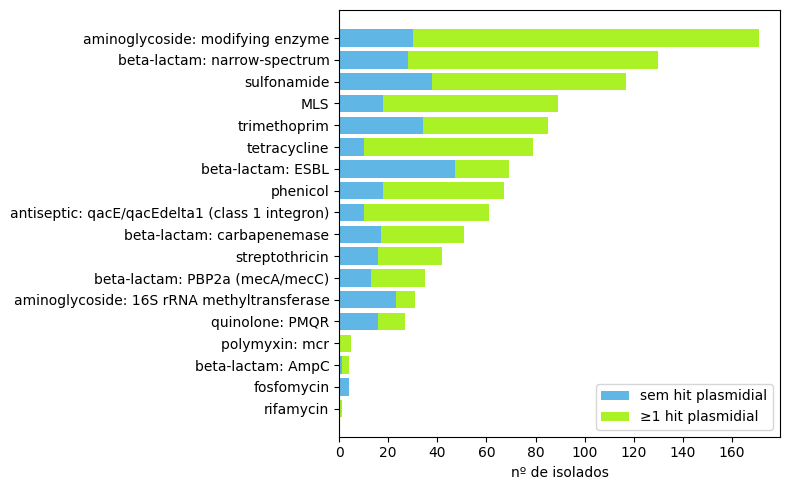

In [40]:
cat_plot = per_cat.copy()
chromo = cat_plot["isolates"] - cat_plot["iso_plasmid"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(cat_plot.index, chromo, color="#60b7e6", label="sem hit plasmidial")
ax.barh(cat_plot.index, cat_plot["iso_plasmid"], left=chromo, color="#aaf125", label="≥1 hit plasmidial")
ax.invert_yaxis(); ax.set_xlabel("nº de isolados"); ax.legend()
plt.tight_layout(); plt.show()

### 5.3 β-lactâmicos

In [21]:
per_cat_beta = per_cat[per_cat.index.str.contains("beta")]
per_cat_beta

,isolates,hits,iso_plasmid,frac_plasmid
acquired_category,,,,
beta-lactam: narrow-spectrum,130,173,102,0.78
beta-lactam: ESBL,69,84,22,0.32
beta-lactam: carbapenemase,51,59,34,0.67
beta-lactam: PBP2a (mecA/mecC),35,35,22,0.63
beta-lactam: AmpC,4,6,3,0.75


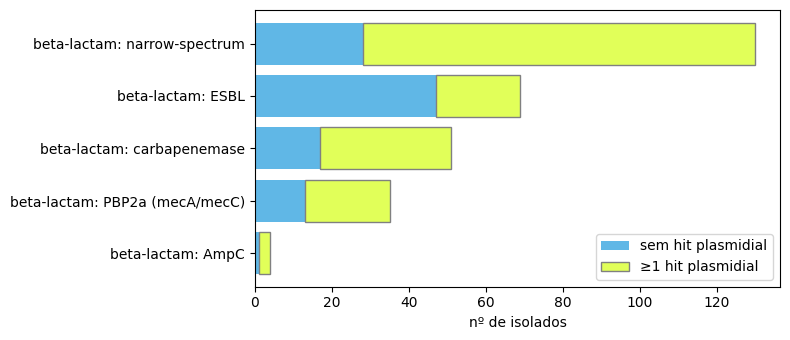

In [22]:
chromo = per_cat_beta["isolates"] - per_cat_beta["iso_plasmid"]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(per_cat_beta.index, chromo, color="#60b7e6", label="sem hit plasmidial")
ax.barh(per_cat_beta.index, per_cat_beta["iso_plasmid"], left=chromo, color="#e1ff59", label="≥1 hit plasmidial", edgecolor="gray")
ax.invert_yaxis(); ax.set_xlabel("nº de isolados"); ax.legend()
plt.tight_layout(); plt.show()

**Interpretação.** ESBL com pouca fração plasmidial e carbapenemase com mais é um padrão *plausível* de se discutir, mas há dois mecanismos que produzem o primeiro sem que o gene "seja cromossômico" na biologia: **(a)** *blaCTX-M* flanqueado por ISEcp1 pode estar de fato inserido no cromossomo (**Shawa et al. 2021**, [DOI](https://doi.org/10.1186/s13756-021-00941-8): inserções cromossômicas de ISEcp1-blaCTX-M em *E. coli* e *E. cloacae*, com outros genes de AMR); **(b)** a região fica num contig curto que o classificador não chama de plasmídeo. Sem long reads, não dá para separar (a) de (b).

### Extra - quais genes plasmidiais em quais species

In [81]:
categorias_destaque = ['aminoglycoside: 16S rRNA methyltransferase',
 'beta-lactam: narrow-spectrum',
 'beta-lactam: carbapenemase',
 'beta-lactam: ESBL',
 'polymyxin: mcr']

In [103]:
def plot_heatmap(df: pd.DataFrame):
    plt.figure(figsize=(9, 9))
    sns.heatmap(df, 
                annot=True, fmt="d", 
                cmap="viridis_r", 
                linewidths=0.5, 
                linecolor="white",
                mask=(df == 0))
    plt.tight_layout(); plt.show()

aminoglycoside: 16S rRNA methyltransferase
Total: 32
Contig cromossomal: 24
Genes: ['rmtD', 'rmtB']


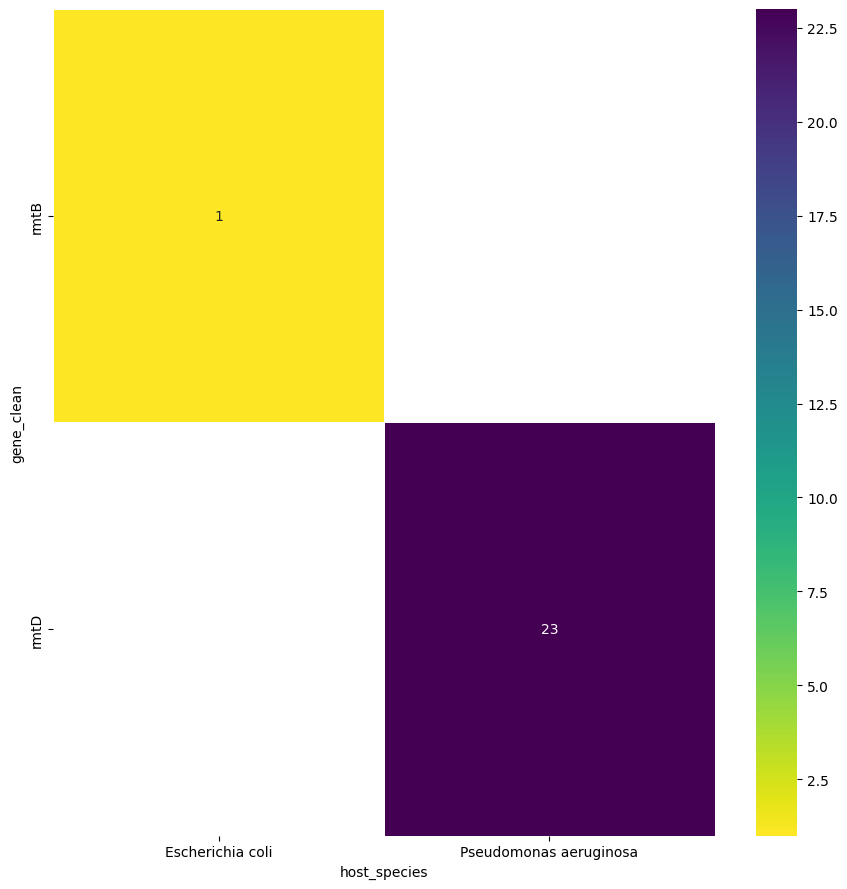

Contig plasmidial: 8
Genes: ['armA', 'rmtD', 'rmtB']


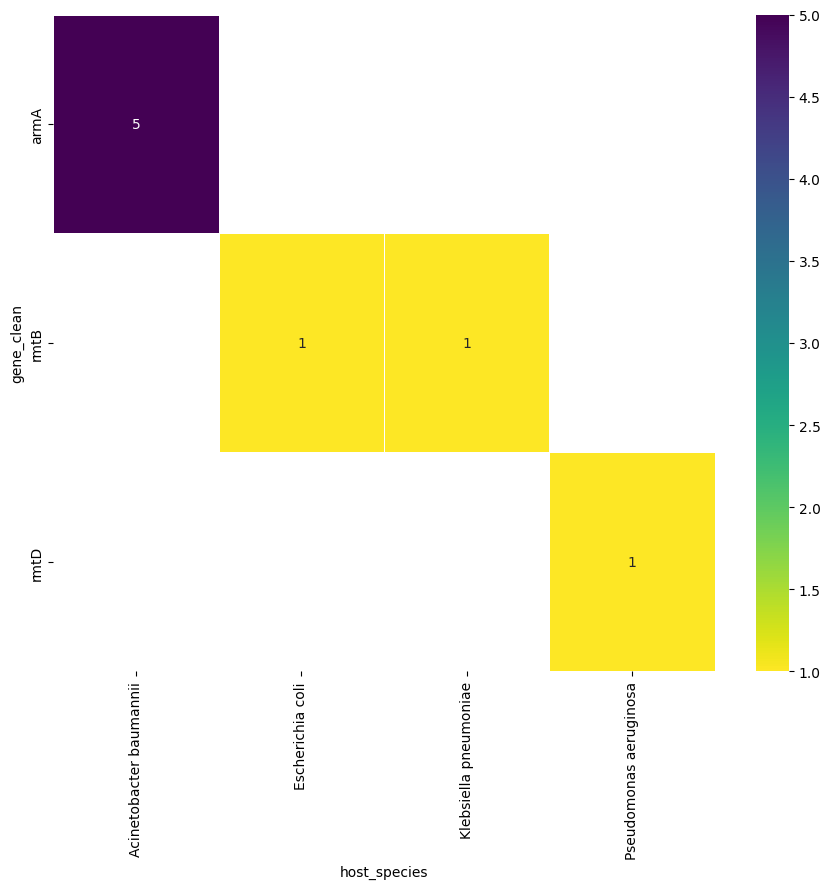


beta-lactam: narrow-spectrum
Total: 205
Contig cromossomal: 86
Genes: ['TEM-183', 'OXA-504-like', 'OXA-9-like', 'TEM-229', 'LAP-2', 'TEM-239', 'TEM-1', 'OXA-10-like', 'TEM-163', 'CARB-3', 'OXA-1-like', 'TEM-244', 'OXA-2-like']


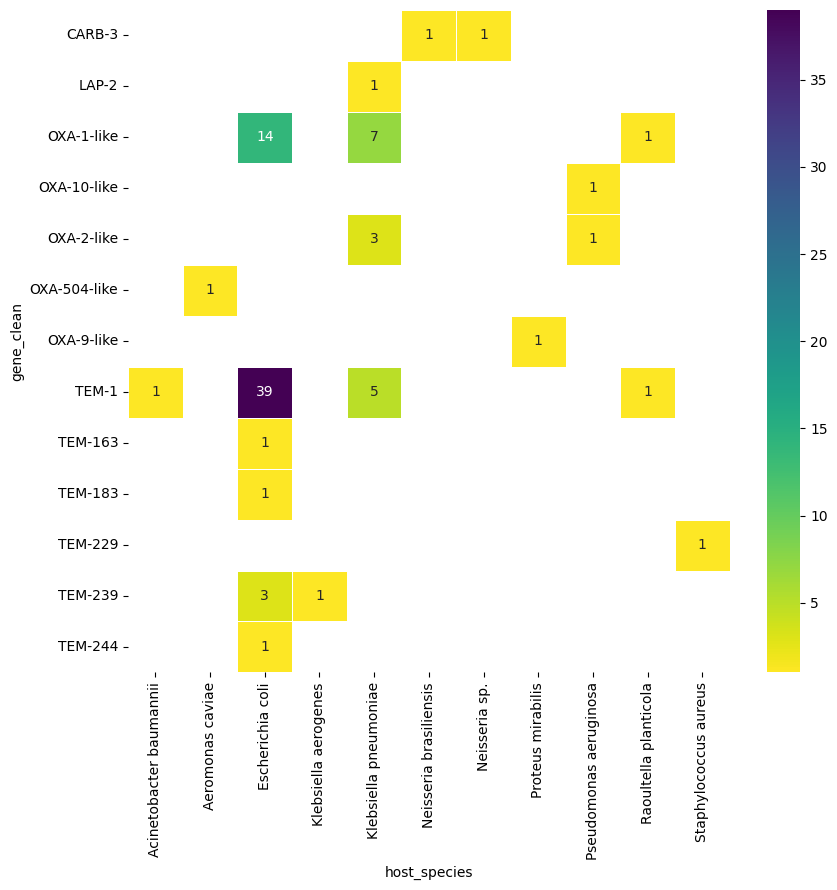

Contig plasmidial: 119
Genes: ['SCO-1', 'TEM-183', 'PC1', 'OXA-9-like', 'OXA-10-like', 'LAP-2', 'TEM-239', 'TEM-1', 'TEM-247', 'OXA-1-like', 'OXA-5-like', 'CARB-16', 'OXA-2-like']


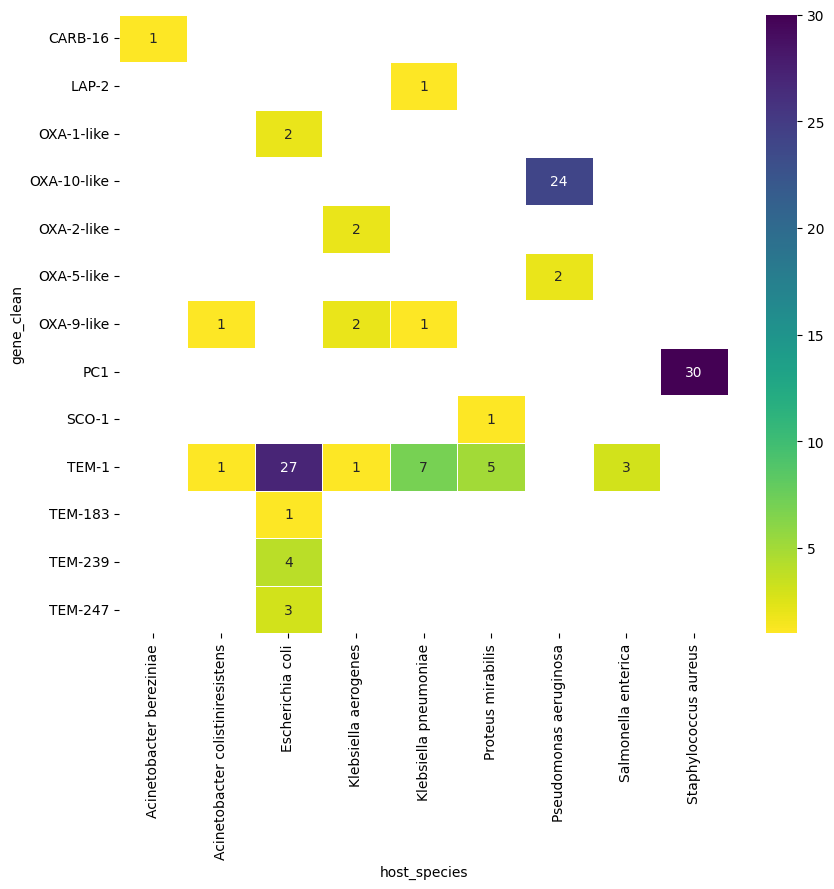


beta-lactam: carbapenemase
Total: 61
Contig cromossomal: 24
Genes: ['NDM-1', 'OXA-58-like', 'KPC-3', 'OXA-23-like', 'IMP-74', 'SPM-1', 'OXA-286-like', 'KPC-2']


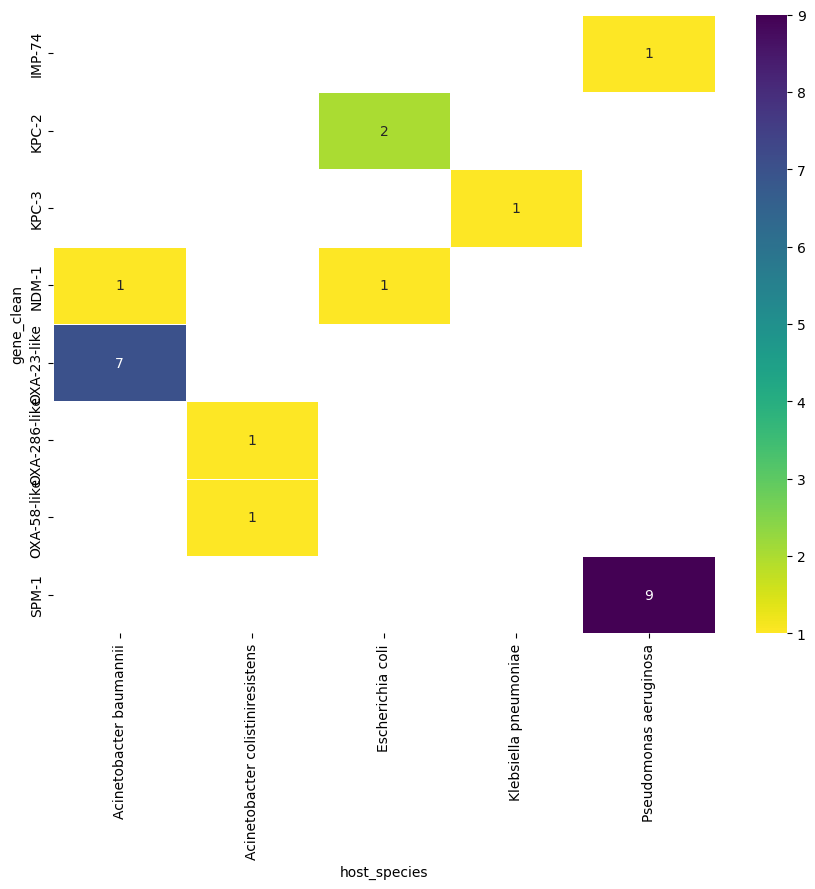

Contig plasmidial: 37
Genes: ['NDM-1', 'OXA-58-like', 'KPC-3', 'OXA-229-like', 'GES-5', 'SPM-1', 'KPC-2']


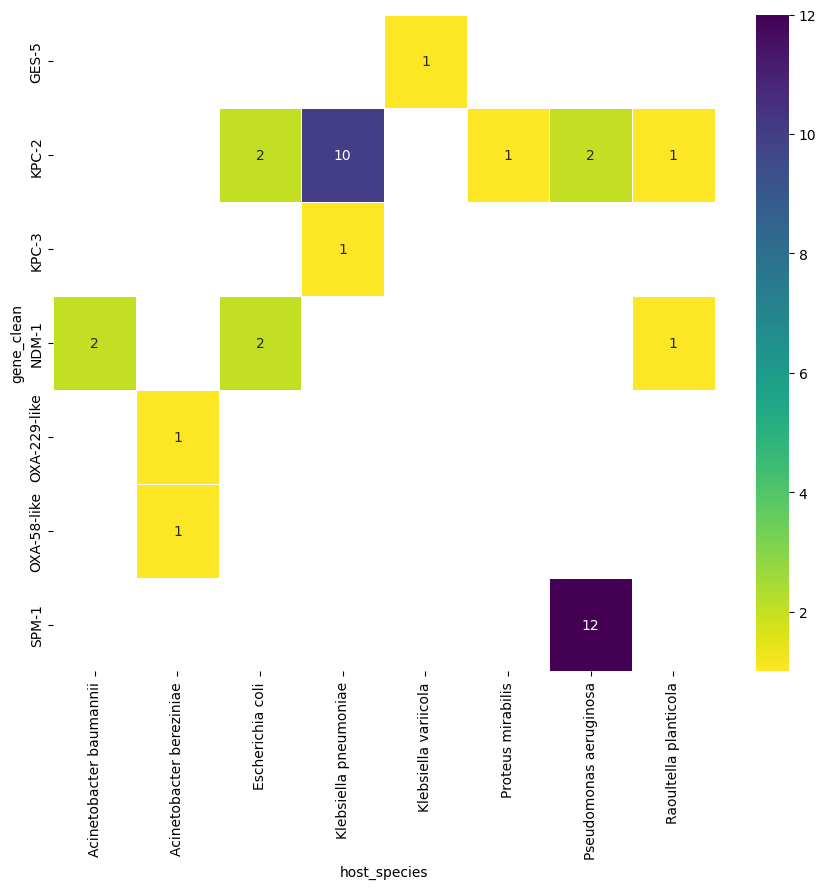


beta-lactam: ESBL
Total: 137
Contig cromossomal: 105
Genes: ['CTX-M-2', 'CTX-M-27', 'CTX-M-157', 'CTX-M-14', 'CTX-M-8', 'CTX-M-24', 'CTX-M-15', 'CTX-M-3', 'CTX-M-55']


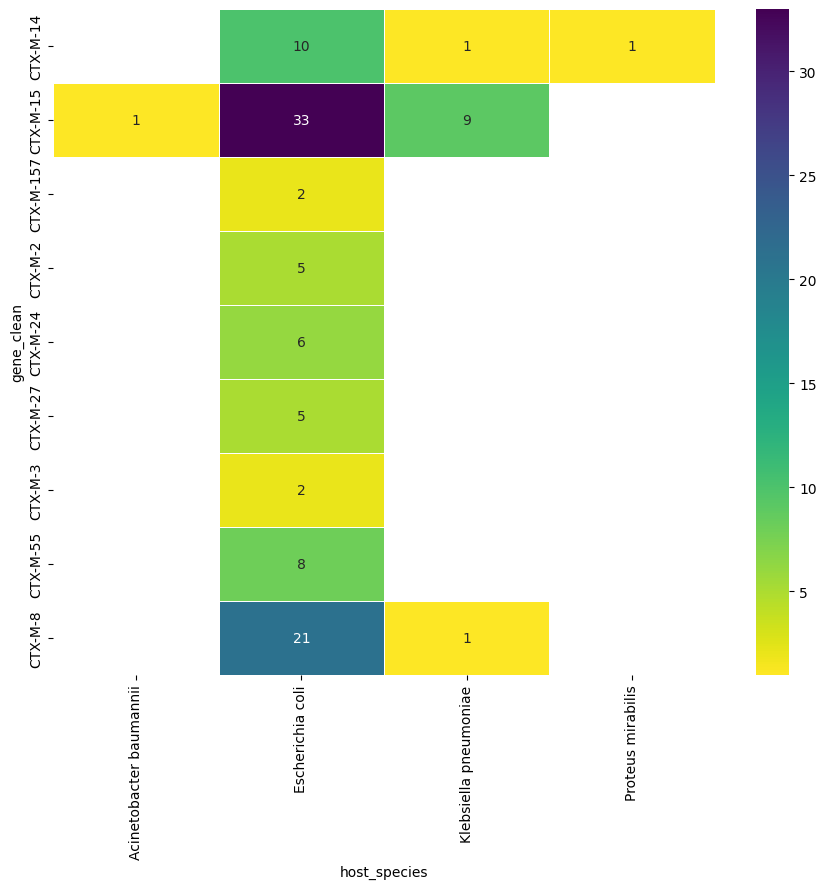

Contig plasmidial: 28
Genes: ['CTX-M-2', 'CTX-M-14', 'CTX-M-8', 'CTX-M-15', 'CTX-M-55']


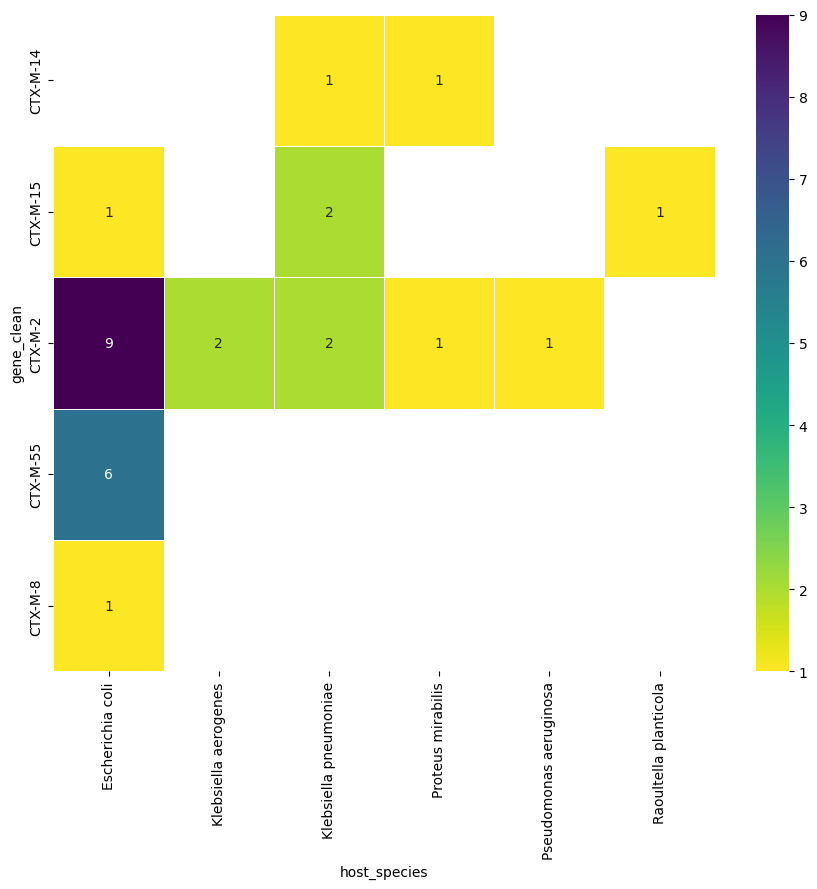


polymyxin: mcr
Total: 5
Contig cromossomal: 0
Genes: []
Contig plasmidial: 5
Genes: ['MCR-1.1', 'MCR-1.34', 'MCR-1.5']


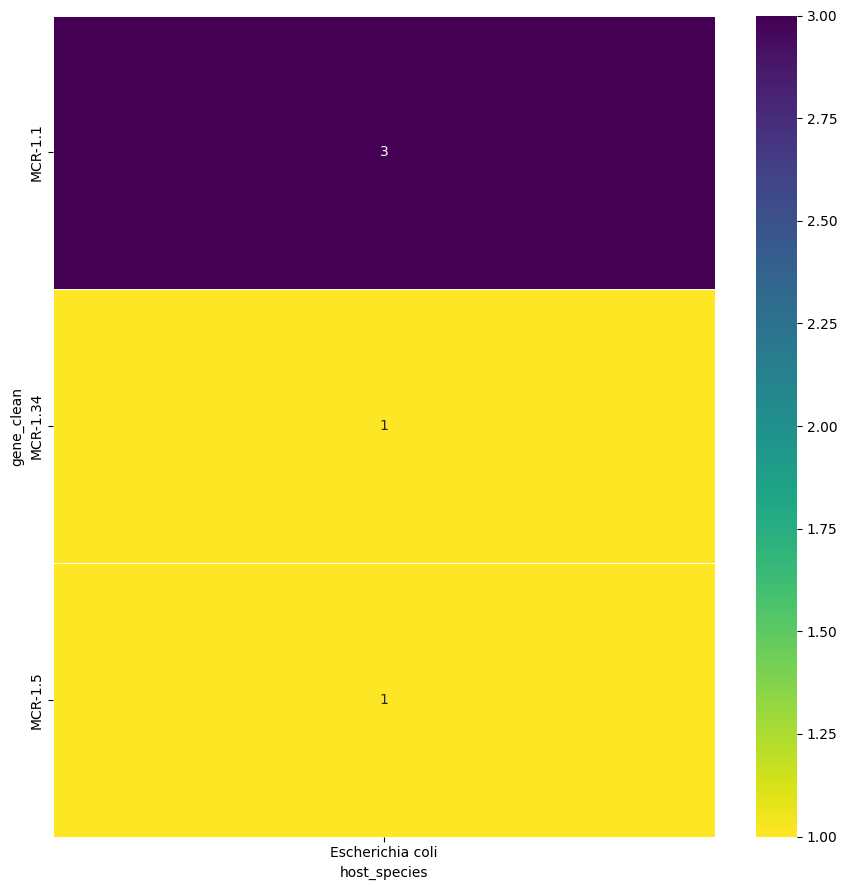

In [ ]:
for cat in categorias_destaque:
    print(cat)
    cat_df = acq[acq['acquired_category'].str.contains(cat)]
    print('Total:', cat_df.shape[0])
    
    cat_cromo = cat_df[cat_df['contig_type'] == 'chromosome']
    genes_cromo = list(set(cat_cromo['gene_clean'].to_list()))

    cat_plasmid = cat_df[cat_df['contig_type'] == 'plasmid']
    genes_plasmid = list(set(cat_plasmid['gene_clean'].to_list()))
    
    
    cat_cromo_crosstab = pd.crosstab(cat_cromo['gene_clean'], cat_cromo['host_species'])
    cat_plasmid_crosstab = pd.crosstab(cat_plasmid['gene_clean'], cat_plasmid['host_species'])
                                     

    print('Contig cromossomal:', cat_cromo.shape[0])
    print('Genes:', genes_cromo)
    if len(genes_cromo) > 0:
        plot_heatmap(cat_cromo_crosstab)

    print('Contig plasmidial:', cat_plasmid.shape[0])
    print('Genes:', genes_plasmid)
    if len(genes_plasmid) > 0:
        plot_heatmap(cat_plasmid_crosstab)

    print()

### 5.4 Genes frequentes e provavelmente plasmidiais (≥5 isolados, ≥70% plasmidial)

In [23]:
mais_comuns = (per_gene[(per_gene["isolates"] >= 5) & (per_gene["frac_plasmid"] >= 0.7)]
               .sort_values("frac_plasmid", ascending=False))
mais_comuns

,isolates,category,bl_function,iso_plasmid,frac_plasmid
gene_clean,,,,,
Mrx,35,MLS,None,35,1.00
CTX-M-2,10,beta-lactam: ESBL,ESBL,10,1.00
armA,5,aminoglycoside: 16S rRNA methyltransferase,None,5,1.00
aadA7,24,aminoglycoside: modifying enzyme,None,24,1.00
KPC-2,15,beta-lactam: carbapenemase,carbapenemase (serine),15,1.00
PC1,30,beta-lactam: narrow-spectrum,narrow-spectrum,30,1.00
floR,12,phenicol,None,12,1.00
cmlA1,5,phenicol,None,5,1.00
tet(A),48,tetracycline,None,47,0.98


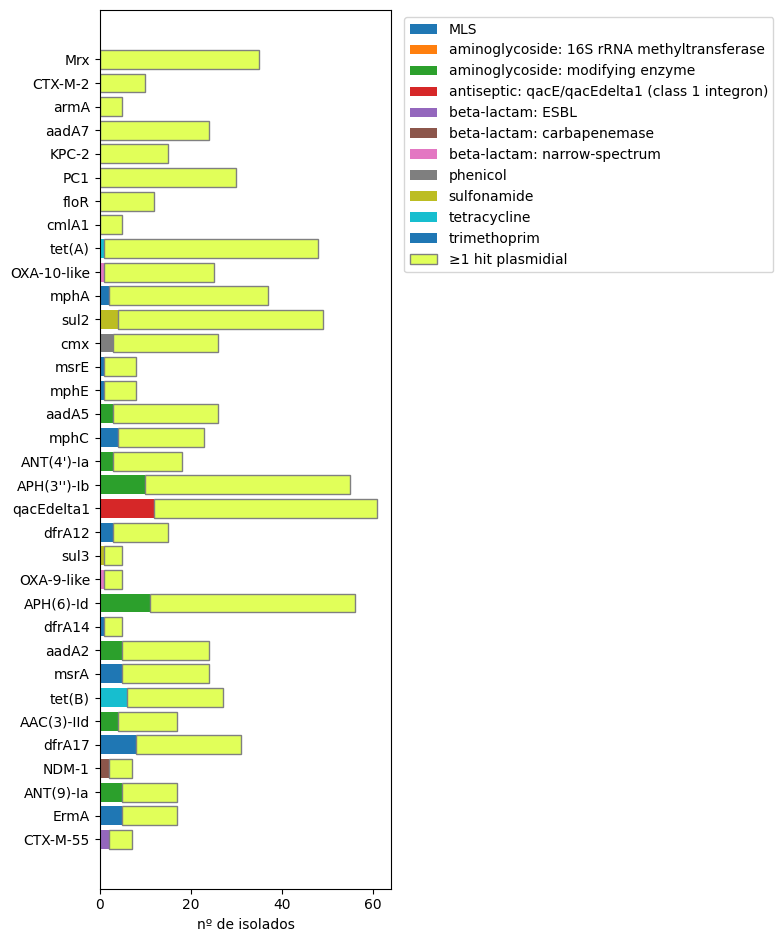

In [24]:
cats = sorted(mais_comuns["category"].dropna().unique())
cmap_cat = {c: plt.cm.tab10(i % 10) for i, c in enumerate(cats)}

chromo = mais_comuns["isolates"] - mais_comuns["iso_plasmid"]
fig, ax = plt.subplots(figsize=(8, max(3, 0.28 * len(mais_comuns))))
ax.barh(mais_comuns.index, chromo, color=mais_comuns["category"].map(cmap_cat), label="sem hit plasmidial")
ax.barh(mais_comuns.index, mais_comuns["iso_plasmid"], left=chromo, color="#e1ff59", edgecolor="gray")
ax.invert_yaxis(); ax.set_xlabel("nº de isolados")
ax.legend(handles=[Patch(facecolor=c, label=k) for k, c in cmap_cat.items()] + [Patch(facecolor="#e1ff59", edgecolor="gray", label="≥1 hit plasmidial")],
          bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

**Interpretação.** Genes como *aadA7*, *Mrx* (MLS), *PC1* (blaZ de *S. aureus*) e *armA* aparecem quase sempre em contig plasmidial. Atenção a **confundimento por espécie/lote**: *PC1* (blaZ) é típico de *S. aureus*, espécie concentrada em um único lote grande, então "30 isolados" pode ser 1 clone; confira a espécie de *Mrx* e de *aadA7* na tabela da seção 7. Cheque o crosstab com lote/espécie (seções 7 e 8) antes de falar em "gene espalhado em plasmídeos".

## 6. Genes-alvo clínicos (carbapenemases, ESBL, 16S MTases, mcr)

In [25]:
TARGET_RX = r"^(?:KPC|NDM|VIM|IMP|SPM|GES)-|^OXA-(?:23|24|40|48|58)(?:-like)?$|^CTX-M-|^arm|^rmt|^MCR-"
targets = per_gene[per_gene.index.str.contains(TARGET_RX)].sort_values("isolates", ascending=False)
targets

,isolates,category,bl_function,iso_plasmid,frac_plasmid
gene_clean,,,,,
CTX-M-15,27,beta-lactam: ESBL,ESBL,4,0.15
rmtD,24,aminoglycoside: 16S rRNA methyltransferase,None,1,0.04
SPM-1,21,beta-lactam: carbapenemase,carbapenemase (MBL),12,0.57
KPC-2,15,beta-lactam: carbapenemase,carbapenemase (serine),15,1.00
CTX-M-8,11,beta-lactam: ESBL,ESBL,1,0.09
CTX-M-14,10,beta-lactam: ESBL,ESBL,2,0.20
CTX-M-2,10,beta-lactam: ESBL,ESBL,10,1.00
OXA-23-like,7,beta-lactam: carbapenemase,carbapenemase (serine),0,0.00
NDM-1,7,beta-lactam: carbapenemase,carbapenemase (MBL),5,0.71


In [26]:
for gname in ["KPC-2", "NDM-1", "armA", "CTX-M-2", "CTX-M-15"]:
    if gname in per_gene.index:
        checklist[f"{gname} on plasmid contigs"] = f"{per_gene.loc[gname, 'frac_plasmid']:.0%} (n={per_gene.loc[gname, 'isolates']})"
mcr = per_gene[per_gene.index.str.startswith("MCR-")]
if len(mcr):
    checklist["mcr on plasmid contigs"] = f"{mcr['frac_plasmid'].mean():.0%} (n={mcr['isolates'].sum()})"
checklist

{'PR isolates': 297,
 'isolates with ≥1 acquired gene': 205,
 'isolates with no acquired gene': 92,
 'distinct acquired genes': 132,
 'acquired hits on plasmid contigs': '49%',
 'isolates with ≥1 acquired hit on a plasmid contig': 177,
 'acquired genes seen on a plasmid contig at least once': '100 of 132',
 'KPC-2 on plasmid contigs': '100% (n=15)',
 'NDM-1 on plasmid contigs': '71% (n=7)',
 'armA on plasmid contigs': '100% (n=5)',
 'CTX-M-2 on plasmid contigs': '100% (n=10)',
 'CTX-M-15 on plasmid contigs': '15% (n=27)',
 'mcr on plasmid contigs': '100% (n=5)'}

**Interpretação.** (Execução anterior.) *KPC-2* 94% plasmidial (n=15), *SPM-1* 57% (n=21), *CTX-M-15* 14% (n=27), *rmtD* 4% (n=24), *MCR-1.x* 100% (n pequeno).

- *KPC-2*: plasmídeo é o esperado (Tn4401 em plasmídeos). Em Enterobactérias do sul do Brasil, **Ribeiro et al. 2013** ([DOI](https://doi.org/10.1099/jmm.0.062141-0)) descrevem 6 plataformas Tn4401 e plasmídeos de ~20 kb não tipáveis, o que ajuda a entender por que o contig plasmidial é curto.
- *SPM-1*: típico de *P. aeruginosa* ST277; está num elemento integrativo-conjugativo (ICE tipo Tn4371), **não** num plasmídeo clássico (**Fonseca et al. 2015**, [DOI](https://doi.org/10.1093/jac/dkv152)). Os 57% provavelmente misturam ICE classificado como plasmídeo e ICE classificado como cromossomo. Contexto de *P. aeruginosa* produtora de SPM-1/IMP/GES em hospital brasileiro: [Polotto et al. 2012](https://doi.org/10.1186/1471-2334-12-176).
- *rmtD* (4%): bate com o "pacote cromossômico" de genes adquiridos do clone ST277 (*rmtD*, *aadA7*, *aph(3')-IIb*, *catB7*, *fosA*, ...): **Galetti et al. 2019**, [DOI](https://doi.org/10.1016/j.jgar.2018.12.009). Note que *aph(3')-IIb*, *catB7* e *fosA* estão no `EXTRA_INTRINSIC` de *P. aeruginosa*; os autores justamente discutem se esse pacote vira "resistoma intrínseco do clone". Vale decidir se isso entra como `intrinsic` na sua definição.
- *CTX-M-15* baixo: ver o comentário de ISEcp1 na seção 5.3.

**Por que não há PCA aqui.** Com ~23 genes (pontos) e dezenas de espécies (variáveis) quase todas com contagem 0 ou 1, o `StandardScaler` por coluna dá o mesmo peso a uma espécie com 1 isolado e a *E. coli*; foi isso que fez *OXA-58-like* aparecer como outlier. A prevalência por espécie + clustermap mostra o mesmo sem esse artefato.

In [27]:
acq_targets = acq[acq["gene_clean"].isin(targets.index)]
# 1 linha por (isolado, gene): conta isolados, não hits
ct = pd.crosstab(
    acq_targets.drop_duplicates(["sample_id", "gene_clean"])["gene_clean"],
    acq_targets.drop_duplicates(["sample_id", "gene_clean"])["host_species"],
)
ct.head()

host_species,Acinetobacter baumannii,Acinetobacter bereziniae,Acinetobacter colistiniresistens,Escherichia coli,Klebsiella aerogenes,Klebsiella pneumoniae,Klebsiella variicola,Proteus mirabilis,Pseudomonas aeruginosa,Raoultella planticola
gene_clean,,,,,,,,,,
CTX-M-14,0,0,0,6,0,2,0,2,0,0
CTX-M-15,1,0,0,17,0,8,0,0,0,1
CTX-M-157,0,0,0,2,0,0,0,0,0,0
CTX-M-2,0,0,0,4,2,2,0,1,1,0
CTX-M-24,0,0,0,3,0,0,0,0,0,0


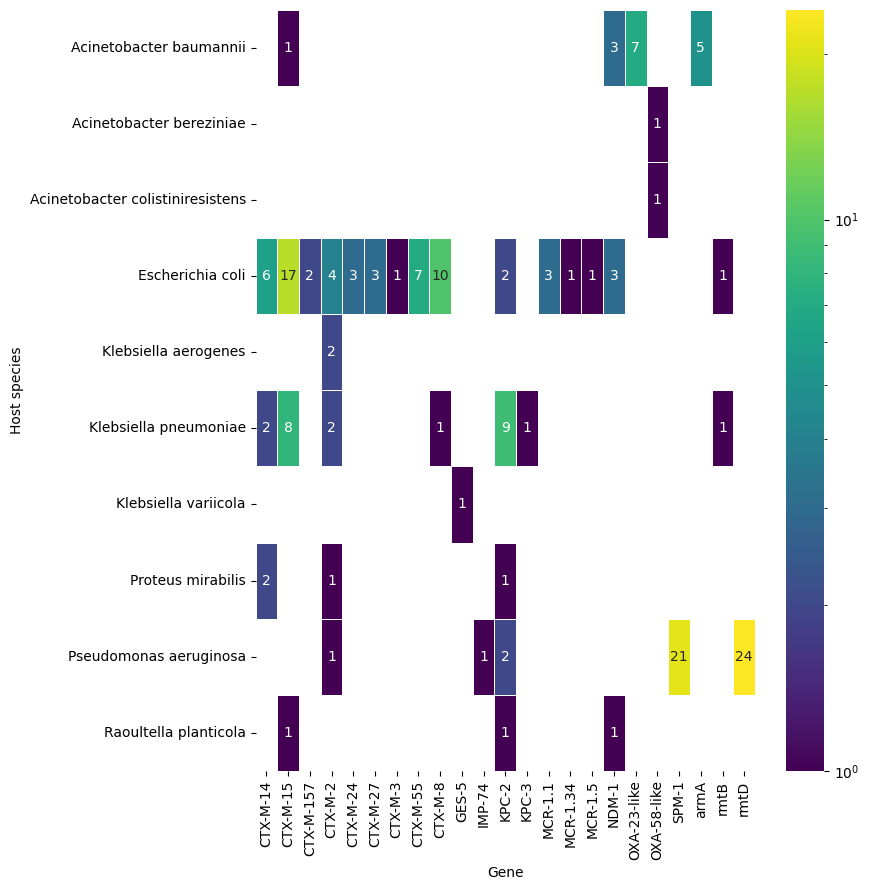

In [28]:
plt.figure(figsize=(9, 9))
sns.heatmap(ct.T, annot=True, fmt="d", cmap="viridis", linewidths=0.5, linecolor="white",
            norm=LogNorm(vmin=1, vmax=max(ct.to_numpy().max(), 2)), mask=(ct.T == 0))
plt.xlabel("Gene"); plt.ylabel("Host species")
plt.tight_layout(); plt.show()

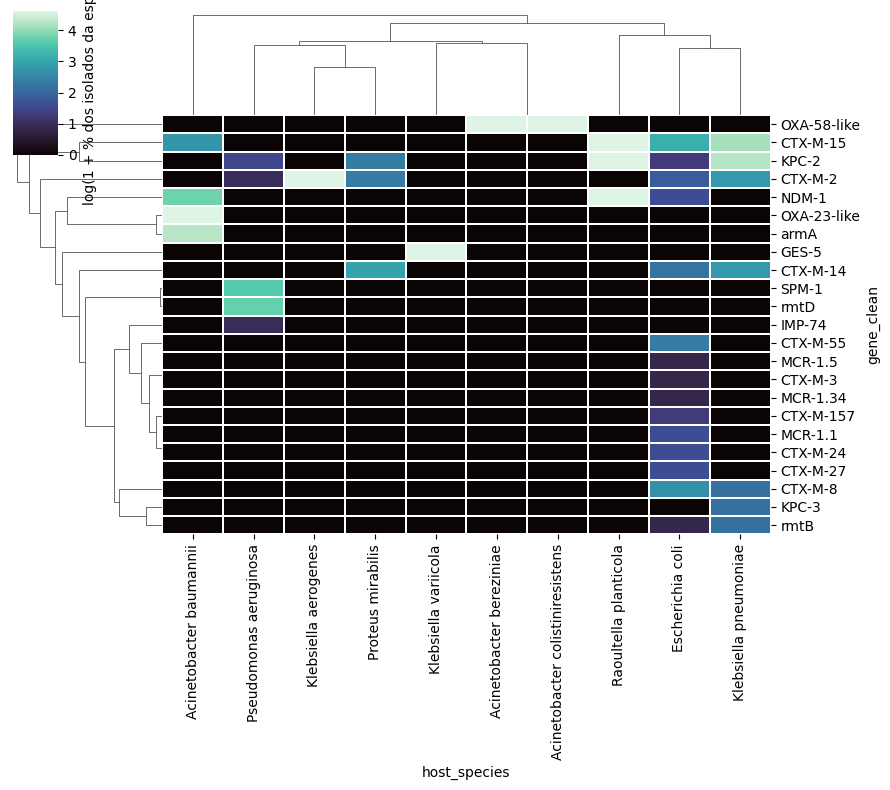

In [29]:
# prevalência dentro de cada espécie (denominador = isolados da espécie no PR) + clustermap
n_sp = pr_ids.groupby("Species").size()
prev = ct.div(n_sp.reindex(ct.columns), axis=1)
sns.clustermap(np.log1p(prev * 100), cmap="mako", figsize=(9, 8), linewidths=0.3,
               cbar_kws={"label": "log(1 + % dos isolados da espécie)"})
plt.show()

**Interpretação.** O heatmap de contagens mostra **quais espécies carregam quais alvos** (ex.: *CTX-M-15* em *E. coli*/*K. pneumoniae*; *SPM-1* em *P. aeruginosa*; *OXA-23-like* em *A. baumannii*). O clustermap de prevalência corrige pelo tamanho da espécie: uma espécie com 4 isolados e 4 hits aparece "cheia", então leia sempre com `n_sp`.

*Para ler (A. baumannii: genes adquiridos em ilhas cromossômicas, relevante para OXA-23/sul/tet aparecerem como "cromossômicos adquiridos"):* **Correa et al. 2024** (Tn6022 e ilhas AbaR em *comM*; [DOI](https://doi.org/10.1093/nar/gkae129)) e **Kumkar et al. 2022** (resistoma intrínseco+adquirido, plasmídeos, IS e AbaRI em 47 genomas; [DOI](https://doi.org/10.3389/fcimb.2022.997897)).

## 7. Foco em plasmídeos: gene × mecanismo × espécie × lote

Aqui `mechanism` é lista (`parse_list_column`), então fazemos `explode` só para a tabela.

In [30]:
plas = acq[(acq["contig_type"] == "plasmid") & acq["lote"].notna()].copy()
print("hits plasmidiais:", len(plas), "| isolados:", plas["sample_id"].nunique())
plas.head()

hits plasmidiais: 1136 | isolados: 177


,ORF_ID,Cut_Off,Pass_Bitscore,Best_Hit_Bitscore,Best_Identities,drug_class,mechanism,amr_gene_family,Predicted_Protein,CARD_Protein_Sequence,...,host_genus,drug_category,high_confidence,bl_function,acquired_category,intrinsic,intrinsic_in,origin,batch,lote
51,JTUI01000085.1_3 # 1905 # 2648 # 1 # ID=107_3;...,Perfect,450,506.523,100.00,[aminoglycoside antibiotic],[antibiotic target alteration],[16S rRNA methyltransferase (G1405)],MSELKEKLLASKKYRDVCPDTIERIWRECSAKFKKEKDVDKAAREA...,MSELKEKLLASKKYRDVCPDTIERIWRECSAKFKKEKDVDKAAREA...,...,Pseudomonas,aminoglycoside,True,NaN,aminoglycoside: 16S rRNA methyltransferase,False,,acquired,59,59 | P. aeruginosa | Sao Paulo (n_PR=6/18)
52,JTUI01000085.1_6 # 4878 # 5759 # -1 # ID=107_6...,Strict,500,542.732,100.00,[sulfonamide antibiotic],[antibiotic target replacement],[sulfonamide resistant sul],MVTVFGILNLTEDSFFDESRRLDPAGAVTAAIEMLRVGSDVVDVGP...,MVTVFGILNLTEDSFFDESRRLDPAGAVTAAIEMLRVGSDVVDVGP...,...,Pseudomonas,sulfonamide,True,NaN,sulfonamide,False,,acquired,59,59 | P. aeruginosa | Sao Paulo (n_PR=6/18)
53,JTUI01000085.1_8 # 7639 # 8436 # -1 # ID=107_8...,Strict,450,523.857,98.87,[aminoglycoside antibiotic],[antibiotic inactivation],[ANT(3'')],MSEKVPAEISVQLSQALNVIGRHLESTLLAVHLYGSALDGGLKPYS...,MSEKVPAEISVQLSQALNGIGRHLESTLLAVHLYGSALDGGLKPYS...,...,Pseudomonas,aminoglycoside,True,NaN,aminoglycoside: modifying enzyme,False,,acquired,59,59 | P. aeruginosa | Sao Paulo (n_PR=6/18)
54,JTUI01000085.1_9 # 8498 # 9298 # -1 # ID=107_9...,Perfect,500,544.658,100.00,"[penicillin beta-lactam, cephalosporin]",[antibiotic inactivation],"[OXA beta-lactamase, OXA-10-like beta-lactamase]",MKTFAAYVITACLSSTALASSITENTFWNKEFSAEAVNGVFVLCKS...,MKTFAAYVITACLSSTALASSITENTFWNKEFSAEAVNGVFVLCKS...,...,Pseudomonas,beta-lactam,True,narrow-spectrum,beta-lactam: narrow-spectrum,False,,acquired,59,59 | P. aeruginosa | Sao Paulo (n_PR=6/18)
129,JTMJ01000107.1_1 # 1227 # 2030 # -1 # ID=10_1;...,Perfect,500,548.125,100.00,[penicillin beta-lactam],[antibiotic inactivation],"[OXA-5-like beta-lactamase, OXA beta-lactamase]",MKTIAAYLVLVFFAGTALSESISENLAWNKEFSSESVHGVFVLCKS...,MKTIAAYLVLVFFAGTALSESISENLAWNKEFSSESVHGVFVLCKS...,...,Pseudomonas,beta-lactam,True,narrow-spectrum,beta-lactam: narrow-spectrum,False,,acquired,59,59 | P. aeruginosa | Sao Paulo (n_PR=6/18)


In [31]:
tabela = (plas.explode("mechanism")
              .groupby(["lote", "host_species", "acquired_category", "mechanism", "gene_clean"])
              .agg(n_isolados=("sample_id", "nunique")).reset_index())
n_lote = lotes.set_index("lote")["n_pr"]
tabela["prev_lote"] = (tabela["n_isolados"] / tabela["lote"].map(n_lote)).round(2)
tabela.sort_values("n_isolados", ascending=False).head(25)

,lote,host_species,acquired_category,mechanism,gene_clean,n_isolados,prev_lote
71,316 | E. coli | Londrina (n_PR=62/62),Escherichia coli,antiseptic: qacE/qacEdelta1 (class 1 integron),antibiotic efflux,qacEdelta1,31,0.50
90,316 | E. coli | Londrina (n_PR=62/62),Escherichia coli,sulfonamide,antibiotic target replacement,sul1,30,0.48
91,316 | E. coli | Londrina (n_PR=62/62),Escherichia coli,sulfonamide,antibiotic target replacement,sul2,28,0.45
93,316 | E. coli | Londrina (n_PR=62/62),Escherichia coli,tetracycline,antibiotic efflux,tet(A),27,0.44
67,316 | E. coli | Londrina (n_PR=62/62),Escherichia coli,aminoglycoside: modifying enzyme,antibiotic inactivation,APH(6)-Id,26,0.42
64,316 | E. coli | Londrina (n_PR=62/62),Escherichia coli,aminoglycoside: modifying enzyme,antibiotic inactivation,APH(3'')-Ib,26,0.42
54,316 | E. coli | Londrina (n_PR=62/62),Escherichia coli,MLS,antibiotic inactivation,Mrx,24,0.39
55,316 | E. coli | Londrina (n_PR=62/62),Escherichia coli,MLS,antibiotic inactivation,mphA,24,0.39
229,615 | S. aureus | Curitiba (n_PR=34/34),Staphylococcus aureus,beta-lactam: narrow-spectrum,antibiotic inactivation,PC1,23,0.68
281,635 | P. aeruginosa | Curitiba (n_PR=53/53),Pseudomonas aeruginosa,beta-lactam: narrow-spectrum,antibiotic inactivation,OXA-10-like,23,0.43


**Interpretação.** Esta tabela é o ponto de partida para hipóteses: "no lote X, *E. coli*, o gene Y (mecanismo Z) aparece em plasmídeo em N de n isolados". `prev_lote` usa `n_PR` como denominador (correção 2). Um mesmo gene aparece em mais de uma linha se tiver mais de um `mechanism`, então não some `n_isolados` entre linhas.

### 7.1 Heatmap por espécie (top 10), colorido por categoria

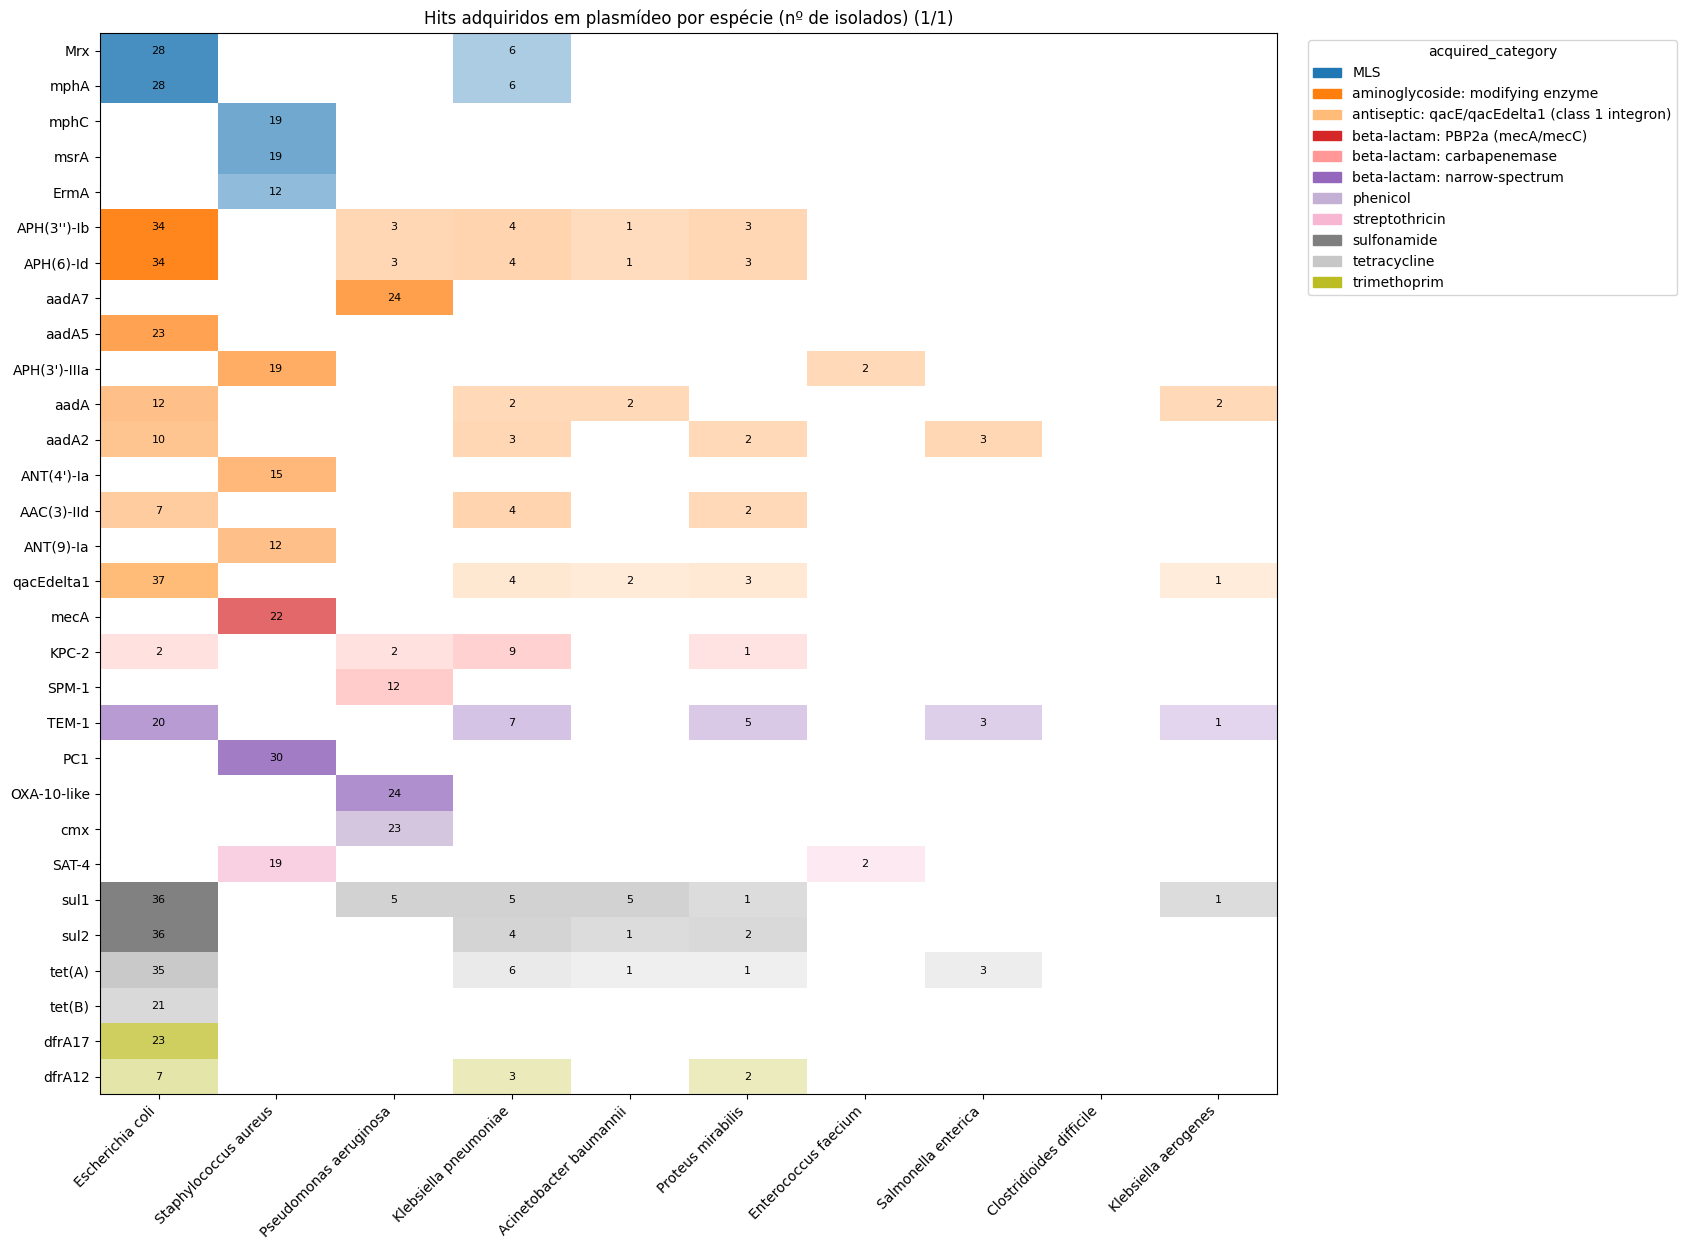

In [32]:
def heatmap_categoria(plas, col, grupos, top_genes=30, titulo="", vmax=None):
    gene_cat = plas.groupby("gene_clean")["acquired_category"].agg(lambda s: s.mode().iat[0])
    cor = {c: plt.cm.tab20.colors[i % 20] for i, c in enumerate(sorted(gene_cat.unique()))}
    vmax = vmax or plas.groupby(["gene_clean", col])["sample_id"].nunique().max()
    for k, cols in enumerate(grupos, 1):
        m = (plas[plas[col].isin(cols)].groupby(["gene_clean", col])["sample_id"].nunique()
               .unstack(fill_value=0).reindex(columns=cols, fill_value=0))
        m = m.loc[m.sum(axis=1).nlargest(top_genes).index]
        m = (m.assign(_cat=gene_cat.reindex(m.index), _tot=m.sum(axis=1))
               .sort_values(["_cat", "_tot"], ascending=[True, False]))
        cat_g = m.pop("_cat"); m = m.drop(columns="_tot")
        img = np.ones((*m.shape, 3))
        for i, gname in enumerate(m.index):
            base = np.array(to_rgb(cor[cat_g[gname]]))
            for j in range(m.shape[1]):
                if m.iat[i, j] > 0:
                    img[i, j] = 1 - (0.25 + 0.75 * m.iat[i, j] / vmax) * (1 - base)
        fig, ax = plt.subplots(figsize=(1.3 * len(cols) + 4, 0.32 * len(m) + 3))
        ax.imshow(img, aspect="auto")
        for i in range(m.shape[0]):
            for j in range(m.shape[1]):
                if m.iat[i, j] > 0:
                    ax.text(j, i, int(m.iat[i, j]), ha="center", va="center", fontsize=8)
        ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
        ax.set_yticks(range(len(m)), m.index)
        ax.set_title(f"{titulo} ({k}/{len(grupos)})")
        ax.legend(handles=[Patch(color=cor[c], label=c) for c in cat_g.unique()],
                  title="acquired_category", bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.tight_layout(); plt.show()

top_sp = list(plas.groupby("host_species")["sample_id"].nunique().nlargest(10).index)
heatmap_categoria(plas, "host_species", [top_sp], titulo="Hits adquiridos em plasmídeo por espécie (nº de isolados)")

**Interpretação.** Cor = categoria do gene; intensidade = nº de isolados. Blocos de cor por espécie indicam **assinatura de resistência plasmidial por espécie** (ex.: aminoglicosídeos+sulfonamida+β-lactâmico estreito em enterobactérias; MLS/tetraciclina/blaZ em estafilococos). Espécies com poucos isolados ficam pálidas por tamanho amostral, não por ausência de genes.

### 7.2 Heatmap por lote (colunas = lotes, em grupos de 8)

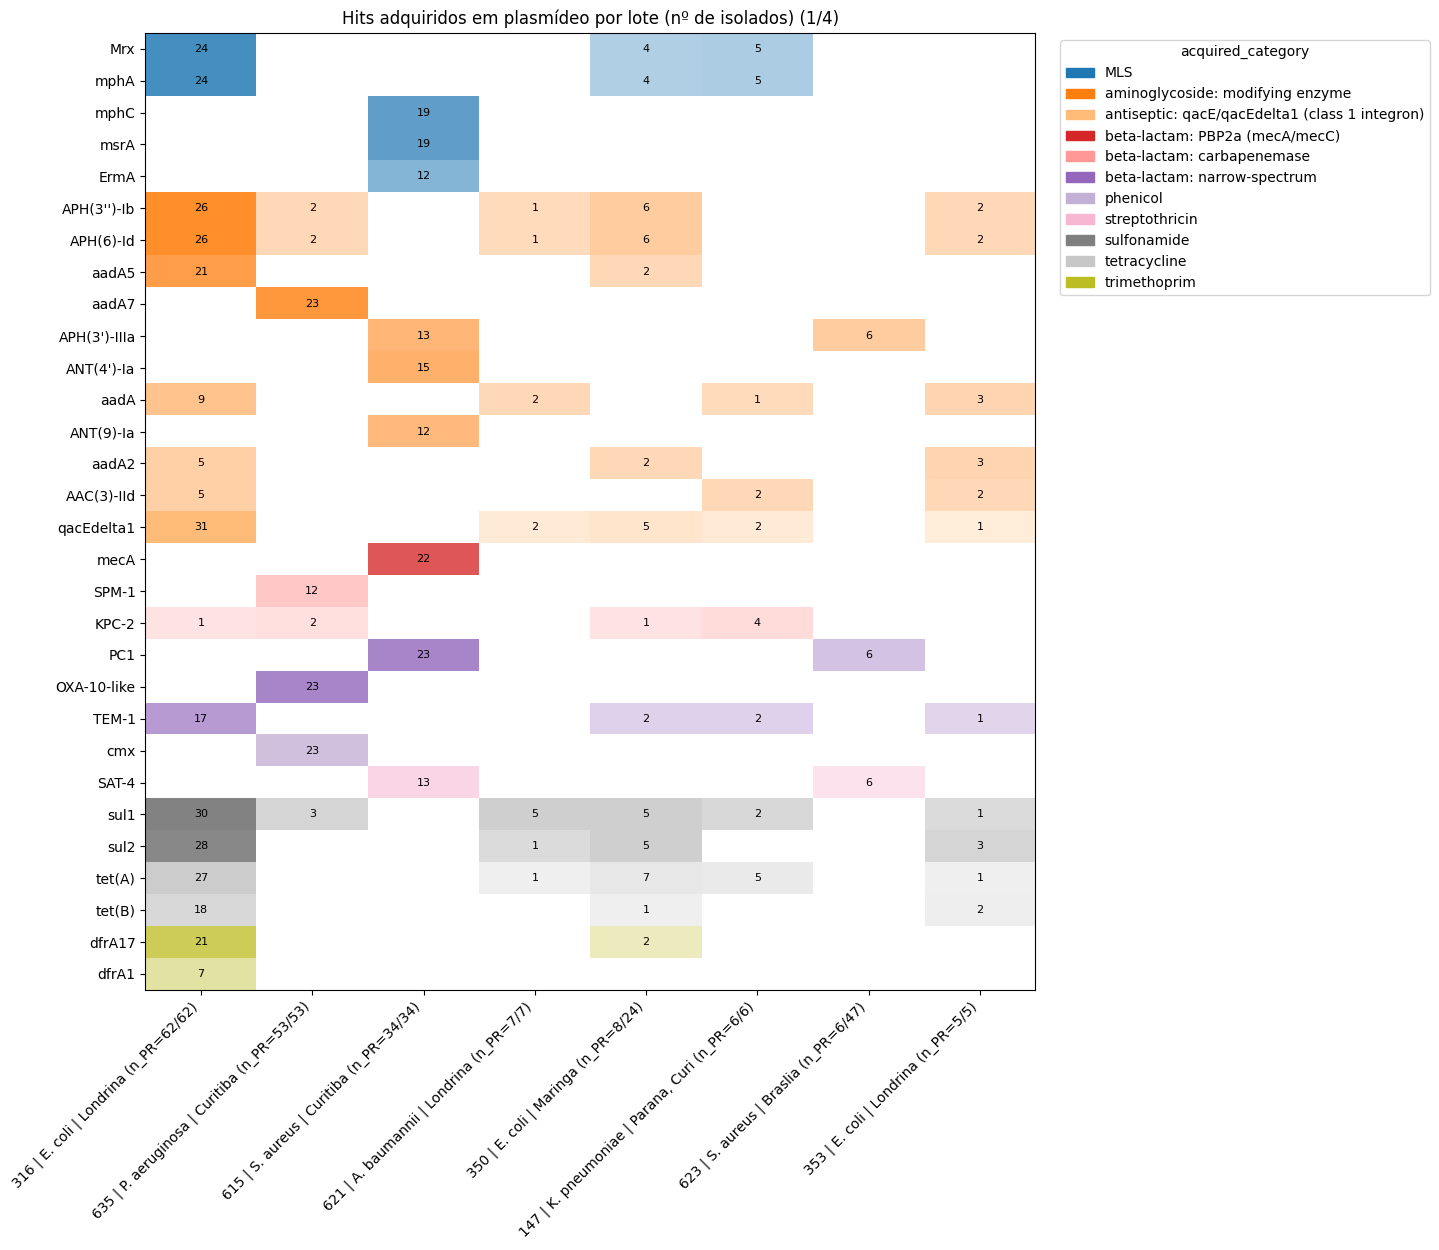

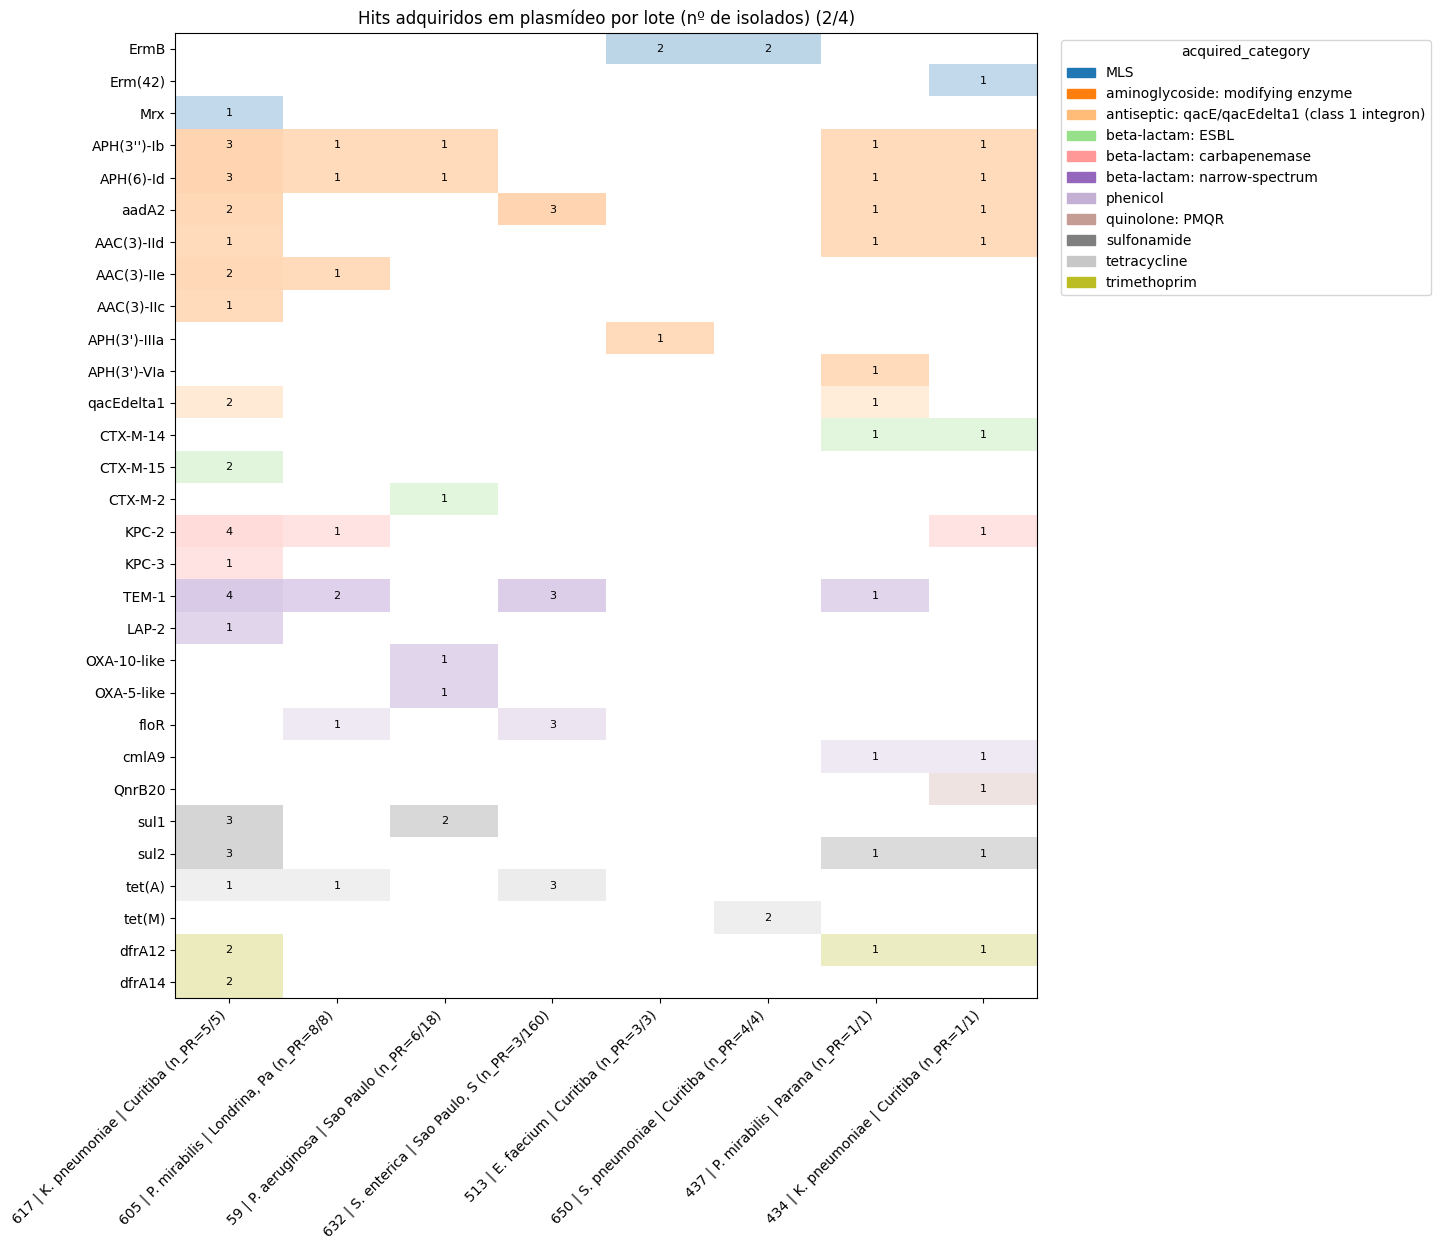

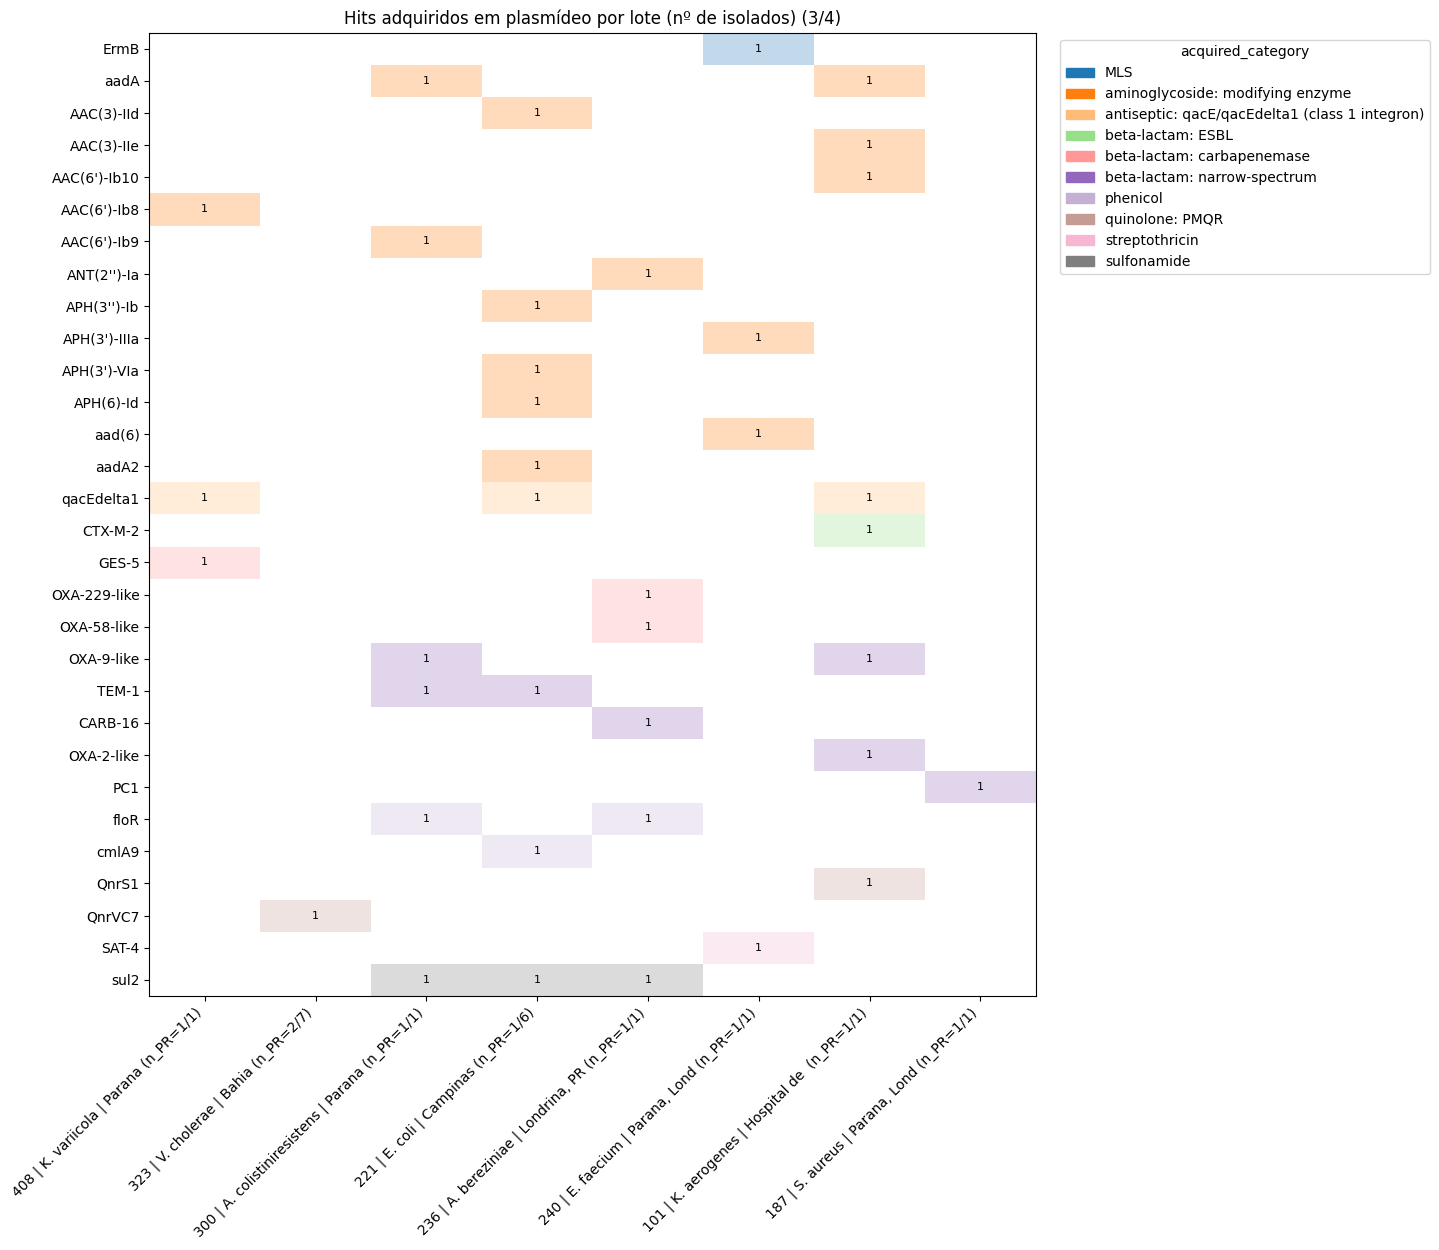

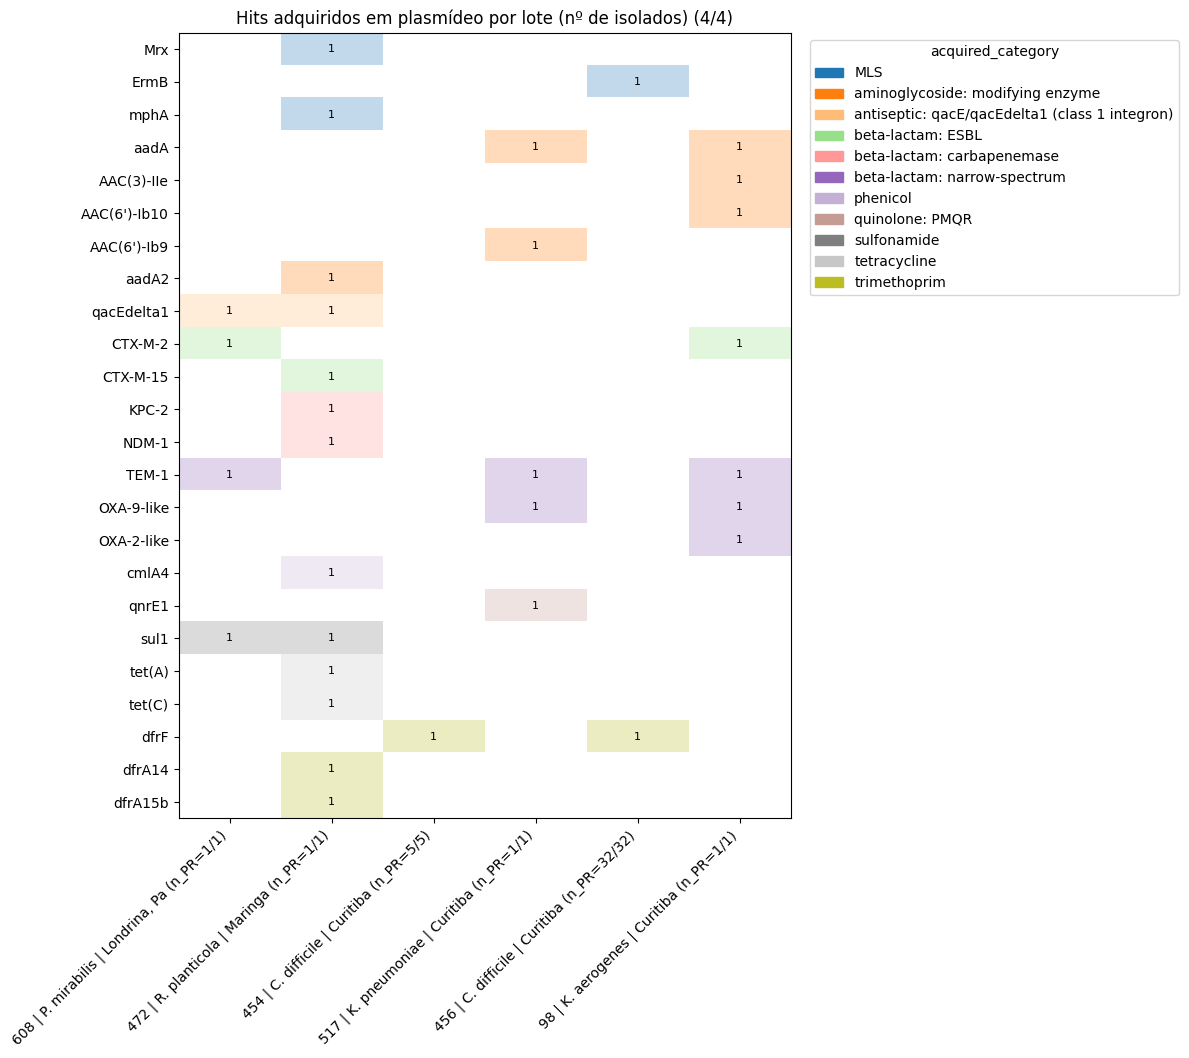

In [33]:
col_ord = plas.groupby("lote")["sample_id"].nunique().sort_values(ascending=False)
N_LOTE = 8
grupos_lote = [list(col_ord.index[i:i + N_LOTE]) for i in range(0, len(col_ord), N_LOTE)]
heatmap_categoria(plas, "lote", grupos_lote, titulo="Hits adquiridos em plasmídeo por lote (nº de isolados)")

**Interpretação.** Se o mesmo conjunto de genes aparece em **todas** as colunas de uma espécie, o padrão é da espécie; se aparece em **um** lote só, é de um clone/hospital (efeito de lote). Lotes grandes dominam a cor; compare com `prev_lote` na tabela acima para não confundir contagem com prevalência.

## 8. Barras empilhadas por espécie: todos × ≥1 adquirido × >1 categoria × plasmidial

Altura = nº de **isolados** (sem normalizar). A barra 1 usa **os 297** isolados do PR (inclui os sem gene adquirido); as outras partem de `acq`.

In [34]:
sp_iso = pr_ids.set_index("sample")["Species"]

n_cat = acq.groupby("sample_id")["acquired_category"].nunique()
conjuntos = {
    "All PR":       set(pr_finais),
    "≥1 acq":       set(acq["sample_id"]),
    ">1 acq categ": set(n_cat[n_cat > 1].index),
    "Plasmidial":   set(acq.loc[acq["contig_type"] == "plasmid", "sample_id"]),
}
tab = pd.DataFrame({f"{k} (n={len(v)})": sp_iso.reindex(list(v)).value_counts() for k, v in conjuntos.items()}).fillna(0)

top10 = tab.iloc[:, 0].nlargest(10).index
tab = pd.concat([tab.loc[top10], tab.drop(top10).sum().rename("Outras").to_frame().T])
tab

,All PR (n=297),≥1 acq (n=205),>1 acq categ (n=186),Plasmidial (n=177)
Escherichia coli,75.0,72.0,69.0,68.0
Pseudomonas aeruginosa,59.0,35.0,29.0,31.0
Staphylococcus aureus,41.0,40.0,37.0,35.0
Clostridioides difficile,39.0,11.0,7.0,2.0
Neisseria meningitidis,26.0,0.0,0.0,0.0
Klebsiella pneumoniae,13.0,13.0,13.0,13.0
Proteus mirabilis,11.0,8.0,6.0,6.0
Acinetobacter baumannii,7.0,7.0,7.0,7.0
Enterococcus faecium,4.0,4.0,4.0,3.0
Streptococcus pneumoniae,4.0,2.0,2.0,2.0


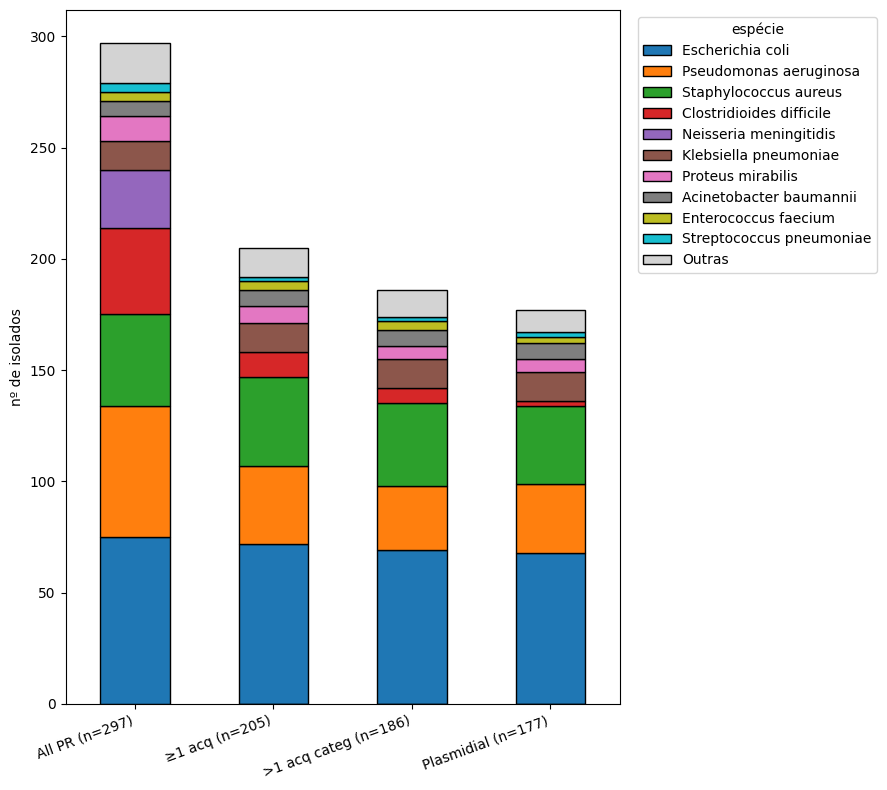

In [35]:
cores = list(plt.cm.tab10.colors) + ["lightgray"]
ax = tab.T.plot(kind="bar", stacked=True, width=0.5, figsize=(9, 8), color=cores, edgecolor="black")
ax.set_ylabel("nº de isolados"); ax.legend(title="espécie", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

**Interpretação.** A queda de 297 → 207 mostra que ~30% dos isolados do PR **não** têm nenhum gene adquirido de alta confiança (provavelmente *C. difficile*, *N. meningitidis* e outras espécies sem cobertura nos dicionários; ver `INTRINSECOS_POR_GENERO`/`EXTRA_ACQUIRED`; ou isolados de fato sensíveis). Compare qual espécie "some" entre a barra 1 e a 2: isso é cobertura do dicionário × biologia. As barras ">1 categoria" e "Plasmidial" mostram quem acumula resistência (multirresistência) e quem a carrega em contigs plasmidiais.

## 9. Checagens de sanidade (rode antes de citar números)

In [36]:
# 9.1 lotes mistos? (lote × espécie dos isolados)
pd.crosstab(res.drop_duplicates("sample_id")["lote"], res.drop_duplicates("sample_id")["host_species"]).loc[lambda d: (d > 0).sum(axis=1) > 1].T.head(20)

lote
host_species
Acinetobacter baumannii
Acinetobacter bereziniae
Acinetobacter colistiniresistens
Aeromonas caviae
Clostridioides difficile
Enterococcus faecium
Escherichia coli
Klebsiella aerogenes
Klebsiella pneumoniae


In [37]:
# 9.2 fração plasmidial por espécie (um valor ~igual em todas = suspeito de viés do classificador)
(acq.assign(p=acq["contig_type"] == "plasmid").groupby("host_species")
    .agg(hits=("p", "size"), frac_hits_plasmid=("p", "mean"), isolados=("sample_id", "nunique"))
    .sort_values("hits", ascending=False).round(2).head(12))

,hits,frac_hits_plasmid,isolados
host_species,,,
Escherichia coli,1425,0.43,72
Staphylococcus aureus,229,0.73,40
Klebsiella pneumoniae,180,0.58,13
Pseudomonas aeruginosa,178,0.57,35
Acinetobacter baumannii,90,0.43,7
Proteus mirabilis,52,0.71,8
Raoultella planticola,22,0.59,1
Klebsiella aerogenes,21,0.81,2
Clostridioides difficile,19,0.16,11


In [38]:
# 9.3 isolados do PR sem hit adquirido: de quais espécies?
sem_acq = sp_iso.loc[~sp_iso.index.isin(acq["sample_id"])]
sem_acq.value_counts().head(10)

Species
Clostridioides difficile    28
Neisseria meningitidis      26
Pseudomonas aeruginosa      24
Proteus mirabilis            3
Escherichia coli             3
Leptospira interrogans       2
Streptococcus pneumoniae     2
Vibrio cholerae              2
Yersinia enterocolitica      1
Staphylococcus aureus        1
Name: count, dtype: int64

**Como ler.**
- **9.1:** lotes com >1 espécie são lotes mistos; a espécie no rótulo é só a moda.
- **9.2:** se todas as espécies têm ~50% plasmidial, o `contig_type` está pouco informativo; se variam muito (ex.: *S. aureus* alto, *E. coli* baixo), a diferença pode ser real ou de montagem (draft vs closed).
- **9.3:** espécies aqui sem adquiridos precisam ser conferidas contra os dicionários antes de concluir "sensível".

**O que falta e exigiria dado novo:** (a) **tamanho do contig** (não está no `res`; só `length_nt` do gene) para filtrar contigs curtos; (b) **qual ferramenta** gerou `contig_type`; (c) **long reads/closed genomes** para as cepas-chave (SPM-1, KPC-2, CTX-M-15), a única forma de separar ICE/ilha/plasmídeo.

## 10. Síntese

1. **Cobertura:** ~70% dos isolados do PR têm ≥1 gene adquirido de alta confiança; os 30% restantes precisam ser auditados (dicionário × sensibilidade real).
2. **Plasmídeo ≠ transferência recente:** o ~49% é um teto afetado por montagem draft; use-o para comparar categorias/espécies, não como estimativa absoluta.
3. **Genes-alvo contam histórias diferentes:** *KPC-2* (plasmídeo/Tn4401), *SPM-1* (ICE em ST277), *rmtD* (pacote cromossômico de ST277), *CTX-M-15* (plasmídeo **ou** inserção cromossômica via ISEcp1).
4. **Efeito de lote/clone:** a prevalência "no PR" é fortemente determinada por poucos lotes grandes; relate sempre `n_PR` e, quando possível, normalize por lote.

## 11. Para ler depois (todas conferidas no PubMed: existência, autores, ano e DOI; a relevância foi avaliada pelo resumo, não pelo texto completo)

| Tema | Referência | Por que ler |
|---|---|---|
| CARD / RGI / prevalência | Alcock BP et al. **CARD 2023**. *Nucleic Acids Res* 51:D690–D699. [10.1093/nar/gkac920](https://doi.org/10.1093/nar/gkac920) | Define modelos (homolog/variant/overexpression), ARO e as estatísticas de prevalência (cromossomo/plasmídeo/WGS) que você usa em `card_prevalence`. |
| Plasmídeos em short reads | Arredondo-Alonso S et al. **On the (im)possibility of reconstructing plasmids from whole-genome short-read sequencing data.** *Microb Genom* 3:e000128 (2017). [10.1099/mgen.0.000128](https://doi.org/10.1099/mgen.0.000128) | Limites de precisão/recall; justifica tratar `contig_type` como teto. |
| Classificação de contigs | Camargo AP et al. **Identification of mobile genetic elements with geNomad.** *Nat Biotechnol* 42:1303–1312 (2023). [10.1038/s41587-023-01953-y](https://doi.org/10.1038/s41587-023-01953-y) | Se o `contig_type` veio de geNomad, descreve o método e o desempenho. |
| *P. aeruginosa* ST277 (Brasil) | Galetti R et al. **SPM-1-producing *P. aeruginosa* ST277 carries a chromosomal pack of acquired resistance genes.** *J Glob Antimicrob Resist* 16:183–186 (2019). [10.1016/j.jgar.2018.12.009](https://doi.org/10.1016/j.jgar.2018.12.009) | Explica *rmtD*/*aadA7*/*aph(3')-IIb*/*catB7*/*fosA* cromossômicos e a discussão de "resistoma intrínseco" do clone. |
| SPM-1 em ICE | Fonseca EL et al. **Full characterization of the integrative and conjugative element carrying blaSPM-1 ... SP/ST277.** *J Antimicrob Chemother* 70:2547–2550 (2015). [10.1093/jac/dkv152](https://doi.org/10.1093/jac/dkv152) | *blaSPM-1* em ICE Tn4371, não plasmídeo. |
| *P. aeruginosa* no Brasil | Polotto M et al. **Detection of *P. aeruginosa* harboring blaCTX-M-2, blaGES-1, blaGES-5, blaIMP-1 and blaSPM-1 ... Brazilian tertiary-care hospital.** *BMC Infect Dis* 12:176 (2012). [10.1186/1471-2334-12-176](https://doi.org/10.1186/1471-2334-12-176) | Contexto clínico/epidemiológico de MBL/ESBL em hospital brasileiro. |
| KPC-2 no sul do Brasil | Ribeiro VB et al. **Molecular characterization of KPC-producing isolates in southern Brazil.** *J Med Microbiol* 62:1721–1727 (2013). [10.1099/jmm.0.062141-0](https://doi.org/10.1099/jmm.0.062141-0) | Plataformas Tn4401 e plasmídeos de ~20 kb (interpretar os 94% plasmidiais). |
| CTX-M cromossômico | Shawa M et al. **Novel chromosomal insertions of ISEcp1-blaCTX-M and diverse AMR genes in Zambian clinical isolates of *E. cloacae* and *E. coli*.** *Antimicrob Resist Infect Control* 10:79 (2021). [10.1186/s13756-021-00941-8](https://doi.org/10.1186/s13756-021-00941-8) | Explica por que CTX-M pode parecer "não plasmidial" (inserções cromossômicas por ISEcp1). Estudo da Zâmbia, não do Brasil. |
| Ilhas AbaR em *A. baumannii* | Correa A et al. **Novel mechanisms of diversity generation in *A. baumannii* resistance islands driven by Tn7-like elements.** *Nucleic Acids Res* 52:3180–3198 (2024). [10.1093/nar/gkae129](https://doi.org/10.1093/nar/gkae129) | Tn6022 em *comM* e formação de ilhas cromossômicas de resistência. |
| Resistoma de *A. baumannii* | Kumkar SN et al. **Diversity of resistant determinants, virulence factors, and mobile genetic elements in *A. baumannii* from India.** *Front Cell Infect Microbiol* 12:997897 (2022). [10.3389/fcimb.2022.997897](https://doi.org/10.3389/fcimb.2022.997897) | Exemplo de análise de genes intrínsecos+adquiridos, plasmídeos, IS e AbaRI no mesmo conjunto. |

*Fonte das referências: PubMed (NCBI), consultado em 05/10/2026.*

**Ainda sem referência verificada (pendente):** listas de genes intrínsecos por espécie com ≥1 artigo por gene (seu pedido anterior sobre PubMed por espécie) — não foi concluída, e não inclui nada aqui para não citar de memória.